# Module 2 — Context Engineering · 15-minute demo
**AnyCompany Bank: what the model reads, what it costs, and how to send less of it**

Kernel **MLADAS (Python 3.12)** · **your AWS account** · `us-east-1` · Amazon Nova only · under **$0.10** per run.

**The story.** AnyCompany Bank's support agent answers from a 6,400-token handbook, remembers Sofia Martinez from
last week and can reach 335 tools, all through one context window. Three changes send the model less, and a ledger
of every call shows what each one saved, or cost, per request.

> **Start early:** run every cell down to **Setup ends here** about **5 minutes before you read on** (~5 s
> of execution). It starts AgentCore Memory (ready in ~4 min) and AgentCore Gateway (~1 min) in the background.

| § | What you will see | Slides |
|---|---|---|
| story, ready check | the story above; both background resources ready | 15 |
| §5.2 | prompt caching: a cache hit vs a plain call | 19–21 |
| discussion | one question to think about | 20 |
| §6.2–6.4 | AgentCore Memory: write, select, and when selecting pays | 25–29 |
| §9.3–9.4 | AgentCore Gateway semantic tool search: 10 tools instead of 335 | 44–46 |
| wrap-up | savings per request; cleanup verified by id | 53 |

<details><summary>Not in this demo (covered in the full module)</summary>

Optimizing the input format (TOON, slides 16–17) · cache killers, time to first token and Claude vs Nova caching ·
memory isolation between customers · compressing context: conversation managers, summarization and offloading large
tool results (slides 30–33) · isolating context across agents and Code Interpreter (slides 34–36) ·
information-dense tools (slides 41–43) and near-duplicate tools (slide 47) · the knowledge check.
</details>

<details><summary>Vocabulary used in the demo (click to open)</summary>

- **Context**: the whole `messages` list the model receives in a single call (slide 5).
- **Cache checkpoint** (`cachePoint`): marks the end of a prompt prefix to reuse. **Cache write / cache read**: the
  first call stores the prefix; later calls within the TTL (time to live, 5 minutes) read it.
- **Namespace**: a path that scopes memory records per customer. **topK / relevance score**: how many records a
  search returns and how similar each one is.
- **MCP**: Model Context Protocol. **Gateway target**: a back end behind AgentCore Gateway. **Semantic tool search**:
  finding the right tools by meaning instead of listing all of them.
- **Fictional data**: AnyCompany Bank, its customers, logs and policies are invented; nothing here is financial advice.
</details>

> **Student copy, executed.** The recorded outputs of one verified run of `M02_context_engineering_demo15.ipynb` (October 2026, us-east-1), so you can read the results without an AWS account. Account ids and IAM identities are masked in the outputs. Not an official AWS training product; AnyCompany Bank, the Octank Credit Bureau and all their data are fictional. To run the demo, open `M02_context_engineering_demo15.ipynb` and read this module's `README.md`. Code: MIT-0 (`LICENSE`) · text: CC BY-SA 4.0 (`LICENSE-CONTENT`).

## §0 — Setup and early start
Every cell in §0 is safe to re-run: it reuses what already exists instead of creating a second copy.

### 0.3 Environment and identity
One `RUN_ID` names every AWS resource this notebook creates, so cleanup by name is exact. `make_agent()` always builds
agents on Amazon Nova (the Strands default model is not Nova), and a **ledger** hook records the tokens, dollars and
latency of every model call. That ledger is the evidence behind every chart in this module.

The next cell loads the shared modules from the repository root (`mladas_common` as `mc`, `mladas_viz`, `bank_data`),
checks the pinned SDK versions and creates `RUN_ID`.

<details><summary>How it works: the shared helpers</summary>

- **`mc.get_session()`**: one boto3 session (`MLADAS_AWS_PROFILE` if you set it, else boto3's standard credential
  chain) pinned to `us-east-1`. Every AWS client in the notebook comes from it.
- **`mc.make_agent(name, system_prompt, model=…, tools=…)`**: a Strands `Agent` on an Amazon Nova `BedrockModel` (it
  refuses any other model id), with no output streamed to the cell, bounded throttling retries and the ledger hook.
- **`LEDGER`**: a Strands `HookProvider` reads `latest_agent_invocation.usage` after every invocation and adds one row:
  scope, agent, model, input / output / cache-read / cache-write tokens, `$` at list price, latency and the
  `correlation_id` passed in `invocation_state`. `LEDGER.scope("…")` tags the rows of a block; `LEDGER.add_service()`
  adds a non-token AgentCore charge (a retrieval, a search) as a row with `model="AgentCore"`.
- **`RUN_ID`**: kept when the cell is re-run (or taken from `M02_RUN_ID`) and appended to `.m02_run_ids`, so
  `teardown_m02.py` can find this run later.
</details>

In [1]:
import os, sys, json, re, time, uuid, warnings, logging
from datetime import datetime, timezone
from pathlib import Path

try:                                               # local Mac: python.org builds ship without trust roots
    import certifi
    os.environ.setdefault("SSL_CERT_FILE", certifi.where())
    os.environ.setdefault("REQUESTS_CA_BUNDLE", certifi.where())
except ImportError:
    pass

NOTEBOOK_DIR = Path.cwd()
DEMOS_ROOT = NOTEBOOK_DIR.parent                   # the repo root: shared helpers + bank data live here
if str(DEMOS_ROOT) not in sys.path:
    sys.path.insert(0, str(DEMOS_ROOT))

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message=".*experimental.*")
for _noisy in ("strands", "strands.tools.mcp.mcp_client", "mcp", "httpx", "client"):
    logging.getLogger(_noisy).setLevel(logging.CRITICAL if "mcp" in _noisy else logging.ERROR)

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
import mladas_common as mc
import mladas_viz as viz
import bank_data as bank
from mladas_common import LEDGER, make_agent, nova, text_of   # LEDGER: one row per model call
from strands import tool

pd.set_option("display.html.use_mathjax", False)  # two '$' amounts in a table must not turn into LaTeX
pd.set_option("display.max_colwidth", 120)
viz.apply_style()

REQUIRED = {"strands-agents": "1.57", "bedrock-agentcore": "1.23", "boto3": "1.43"}   # as verified
versions = mc.stack_versions()
for _pkg, _want in REQUIRED.items():
    assert versions[_pkg].startswith(_want), f"{_pkg} {versions[_pkg]} found, {_want}.x expected — run ../setup_env.sh"
import jinja2, networkx, mcp                        # noqa: F401  optional deps the sections need (fail here, not later)

_ident = mc.whoami()                               # STS GetCallerIdentity on mc.AWS_PROFILE (or the standard chain)
SESSION = mc.get_session()                         # the one boto3 session (profile + us-east-1) of every cell
ACCOUNT, REGION = _ident["account"], _ident["region"]
# Re-running this cell keeps the same RUN_ID, so resources already created stay reachable for cleanup.
RUN_ID = globals().get("RUN_ID") or os.getenv("M02_RUN_ID") or \
    f"{datetime.now(timezone.utc):%Y%m%d-%H%M%S}-{uuid.uuid4().hex[:4]}"
with open(NOTEBOOK_DIR / ".m02_run_ids", "a") as _run_ids:  # lets `teardown_m02.py --last` find this run later
    _run_ids.write(RUN_ID + "\n")
FORCE_FAIL = os.getenv("M02_FORCE_FAIL", "")               # fail one on purpose: memory | gateway

print(f"AWS identity : {mc.mask_account(_ident['arn'], ACCOUNT)}  (profile={_ident['profile']}, region={REGION})")
print(f"RUN_ID       : {RUN_ID}")
print("SDK stack    :", "  ".join(f"{k}={v}" for k, v in versions.items()))
if FORCE_FAIL:
    print(f"⚠ M02_FORCE_FAIL={FORCE_FAIL}: that dependency will fail on purpose to show the fallback path.")

AWS identity : arn:aws:iam::************:user/<you>  (profile=<your profile>, region=us-east-1)
RUN_ID       : 20261029-234713-a903
SDK stack    : strands-agents=1.57.1  strands-agents-tools=0.8.9  bedrock-agentcore=1.23.1  a2a-sdk=0.3.26  boto3=1.43.103


### 0.5 Measuring tokens when CountTokens says no
The deck suggests the Bedrock **CountTokens** API to size a prompt before sending it (slide 5). The next cell tries it
on Nova 2 Lite.

> **Deck vs 2026:** The deck says to estimate prompt size with CountTokens. In September 2026, CountTokens rejects
> every Amazon Nova model id, and a chars/4 estimate was 18–43% off for Nova 2 Lite in our test runs. So this module
> *measures*: `mc.count_tokens()` sends one Converse request with `maxTokens=1` and reads `usage.inputTokens`. It costs
> the input tokens (about $0.002 for the 6,400-token handbook), results are cached, and each probe is a ledger row.

In [2]:
from botocore.exceptions import ClientError

try:
    SESSION.client("bedrock-runtime").count_tokens(
        modelId=mc.MODELS["nova-2-lite"],
        input={"converse": {"messages": [{"role": "user", "content": [{"text": "Hi"}]}]}})
    print("CountTokens answered for Nova — the service changed since Sept 2026; mc.count_tokens still works.")
except ClientError as e:
    print(f"CountTokens on Nova 2 Lite -> {e.response['Error']['Code']}: {e.response['Error']['Message']}")

count_tokens = mc.count_tokens                     # measured: maxTokens=1 Converse call minus a baseline
HANDBOOK = bank.load_handbook()                    # the static service handbook SH-2026.3 (§5 caches it)
BANK_API_TOOLS = [tool(fn) for fn in bank.BACKEND_APIS]   # the 13 back-end APIs as Strands tools
with LEDGER.scope("§0 probe"):
    token_facts = pd.DataFrame([
        {"what": "'Why was my card declined?' as a user message",
         "tokens": count_tokens("Why was my card declined?")},
        {"what": "hidden overhead Nova 2 Lite adds to every request",
         "tokens": count_tokens(".", include_overhead=True) - 1},       # a '.' request, minus the '.' itself
        {"what": f"service handbook {bank.HANDBOOK_VERSION} ({len(HANDBOOK):,} characters)", "tokens": count_tokens(HANDBOOK)},
        {"what": "13 bank back-end APIs as tool definitions", "tokens": count_tokens(tools=BANK_API_TOOLS)},
    ])
display(token_facts.style.format({"tokens": "{:,}"}).hide(axis="index"))
print(f"Measuring cost {LEDGER.df('§0 probe')['cost_usd'].sum() * 100:.2f} cents "
      f"({len(LEDGER.df('§0 probe'))} probe calls; repeats are cached).")
if (_overhead := token_facts["tokens"].iloc[1]) != mc.NOVA_BASE_OVERHEAD["nova-2-lite"]:   # recorded 2026-09-26
    print(f"⚠ The overhead measured {_overhead} tokens today, not {mc.NOVA_BASE_OVERHEAD['nova-2-lite']}; "
          "count_tokens() subtracts the live value.")

CountTokens on Nova 2 Lite -> ValidationException: The provided model doesn't support counting tokens.


what,tokens
'Why was my card declined?' as a user message,5
hidden overhead Nova 2 Lite adds to every request,46
"service handbook SH-2026.3 (28,205 characters)","6,410"
13 bank back-end APIs as tool definitions,"1,811"


Measuring cost 0.28 cents (4 probe calls; repeats are cached).


### 0.6 Early start: AgentCore Memory
§6 needs a memory that already knows last week. A memory with long-term strategies takes about **2.5 minutes** to
become `ACTIVE`, and long-term extraction runs asynchronously after that, so we start both **now, in the background**.
Namespaces are per customer (`/customers/{actorId}/...`): that is what keeps Aisha's memories out of Sofia's context.

The first cell below defines the memory (`create_bank_memory()`: three long-term **strategies**, each with its own
namespace) and the seeding (`seed_last_week()`); the collapsed cell runs both on a background thread (`MemoryBootstrap`).

<details><summary>How it works: creating and seeding the memory</summary>

- `CreateMemory` returns at once with status `CREATING`. `MemoryBootstrap` polls `GetMemory` every 10 s until `ACTIVE`
  (it gives up after 420 s), then seeds. It never raises: the notebook reads `.status`, `.error` and `.progress()`.
- `seed_last_week()` writes one `CreateEvent` per user turn + reply, backdated with `eventTimestamp` to the day of
  the chat and paced at 0.25 s (at most 5 per second per actor and session). The strategies extract records from
  these events on their own, asynchronously.
- Four records the application already knows (settings pages, a compliance flag) go in with
  `BatchCreateMemoryRecords`, straight into their namespace: no extraction. One is an older, conflicting preference
  (phone calls, 2025).
- `eventExpiryDuration=7` keeps raw events for 7 days; a `clientToken` makes a retried create idempotent.
- Re-running the cell reuses `memory_job` instead of creating a second memory.
</details>

<details><summary>What we write now, and why (slide 26)</summary>

| What we write now | API | Where it lands | Why (slide 26) |
|---|---|---|---|
| Sofia's 30-turn chat from 2026-09-19 and Aisha's 8-turn chat from 2026-09-17 | `CreateEvent` (short-term events) | strategies extract **facts**, **preferences** and a **session summary** | knowledge that appeared in conversation |
| Sofia's settings page and a compliance flag | `BatchCreateMemoryRecords` (direct write) | `/customers/cust-1001/preferences/` and `.../compliance/` | the application already knows these facts; don't make a model re-learn them |

</details>

In [3]:
from datetime import timedelta

MEMORY_NAME = "MLADAS_M02_" + RUN_ID.replace("-", "_")     # [a-zA-Z][a-zA-Z0-9_]{0,47}: no hyphens
SOFIA_ACTOR, AISHA_ACTOR = "cust-1001", "cust-1003"         # actorId = the customer; lowercase ids
MEMORY_NAMESPACES = {
    "preferences": "/customers/{actorId}/preferences/",
    "facts":       "/customers/{actorId}/facts/",
    "sessions":    "/customers/{actorId}/sessions/{sessionId}/",
    "compliance":  "/customers/{actorId}/compliance/",      # written directly; no strategy owns it
}
# Long-term strategies: each extracts one kind of record from the events into its own namespace (slide 25)
MEMORY_STRATEGIES = [
    {"userPreferenceMemoryStrategy": {"name": "CustomerPreferences", "namespaceTemplates": [MEMORY_NAMESPACES["preferences"]]}},
    {"semanticMemoryStrategy":       {"name": "CustomerFacts",       "namespaceTemplates": [MEMORY_NAMESPACES["facts"]]}},
    {"summaryMemoryStrategy":        {"name": "SessionSummaries",    "namespaceTemplates": [MEMORY_NAMESPACES["sessions"]]}},
]
# Control plane (create / get / delete the memory) vs data plane (events, records, retrieval)
memory_control, memory_data = SESSION.client("bedrock-agentcore-control"), SESSION.client("bedrock-agentcore")


def create_bank_memory() -> str:
    """CreateMemory returns at once (status CREATING)."""
    return memory_control.create_memory(
        name=MEMORY_NAME, description="MLADAS M02 - AnyCompany Bank customer memory",
        eventExpiryDuration=7,                                      # days of raw events (3..365)
        memoryStrategies=MEMORY_STRATEGIES,
        indexedKeys=[{"key": "category", "type": "STRING"}, {"key": "priority", "type": "NUMBER"}],
        tags={"project": "mladas", "module": "M02", "run_id": RUN_ID}, clientToken=str(uuid.uuid4()),
    )["memory"]["id"]


def memory_namespace(kind: str, actor: str) -> str:
    return MEMORY_NAMESPACES[kind].replace("{actorId}", actor)


def seed_last_week(memory_id: str) -> dict:
    """Write last week's chats as events (extraction starts on its own) and the settings-page facts as records."""
    for actor, session_id, turns, day in ((SOFIA_ACTOR, "sofia-2026-09-19", bank.SOFIA_LAST_SESSION, 19),
                                         (AISHA_ACTOR, "aisha-2026-09-17", bank.AISHA_LAST_SESSION, 17)):
        start = datetime(2026, 9, day, 15, 0, tzinfo=timezone.utc)
        for i in range(0, len(turns) - 1, 2):                        # one event = one user turn + the reply
            memory_data.create_event(
                memoryId=memory_id, actorId=actor, sessionId=session_id,
                eventTimestamp=start + timedelta(seconds=40 * i),   # backdated to the day of the chat
                payload=[{"conversational": {"role": "USER", "content": {"text": turns[i]["text"]}}},
                         {"conversational": {"role": "ASSISTANT", "content": {"text": turns[i + 1]["text"]}}}],
                clientToken=str(uuid.uuid4()))
            time.sleep(0.25)                                         # CreateEvent: at most 5 TPS per actor+session
    events = (len(bank.SOFIA_LAST_SESSION) + len(bank.AISHA_LAST_SESSION)) // 2     # billed per event
    LEDGER.add_service("memory_event", events, mc.AGENTCORE_PRICES["memory_event"], note="§0.6 seeding")

    def record(rid, text, kind, actor, category, priority, ts=datetime(2026, 9, 20, 9, 0, tzinfo=timezone.utc)):
        return {"requestIdentifier": rid, "namespaces": [memory_namespace(kind, actor)], "content": {"text": text},
                "timestamp": ts, "metadata": {"category": {"stringValue": category}, "priority": {"numberValue": priority}}}

    # Direct writes: each record lands in its namespace as written, with no extraction step
    written = memory_data.batch_create_memory_records(memoryId=memory_id, clientToken=str(uuid.uuid4()), records=[
        record("sofia-channel", "Settings page (2026-09-20): Sofia Martinez's preferred contact channel is email "
               "only; never SMS.", "preferences", SOFIA_ACTOR, "preference", 8),
        record("sofia-old-phone", "Preference recorded 2025-03-01: Sofia Martinez prefers phone calls to her mobile "
               "for account matters.", "preferences", SOFIA_ACTOR, "preference", 8,
               ts=datetime(2025, 3, 1, 12, 0, tzinfo=timezone.utc)),
        record("sofia-do-not-solicit", "Compliance flag since 2025-02-01: Sofia Martinez is on the do-not-solicit "
               "list. Never offer new products (cards, certificates, loans) unless she asks.",
               "compliance", SOFIA_ACTOR, "compliance", 10),
        record("aisha-channel", "Settings page (2026-09-15): Aisha Patel prefers in-app notifications.",
               "preferences", AISHA_ACTOR, "preference", 8),
    ])
    return {"events": events,
            "records": {r["requestIdentifier"]: r["memoryRecordId"] for r in written["successfulRecords"]}}

In [4]:
# Background job (collapsed): MemoryBootstrap, wait_for_memory() and the start-once logic of §0.6.
import threading


class MemoryBootstrap:
    """Background job: CreateMemory -> ACTIVE -> seed_last_week(). Never raises; read .status / .error / .progress()."""

    def __init__(self, force_fail: bool = False):
        self.memory_id: str | None = None
        self.status, self.error, self.seeded, self.adopted = "STARTING", None, None, False
        self._log: list[tuple[float, str, str]] = []
        self._t0 = time.time()
        self._force_fail = force_fail
        self.thread = threading.Thread(target=self._run, name="m02-memory", daemon=True)

    def _step(self, step: str, msg: str = "") -> None:
        self.status = step
        self._log.append((round(time.time() - self._t0, 1), step, msg))

    def _run(self) -> None:
        try:
            if self._force_fail:
                raise RuntimeError("forced by M02_FORCE_FAIL=memory")
            self.memory_id = create_bank_memory()
            self._step("CREATING", self.memory_id)
            while (state := memory_control.get_memory(memoryId=self.memory_id)["memory"]["status"]) != "ACTIVE":
                if state == "FAILED" or time.time() - self._t0 > 420:
                    raise RuntimeError(f"memory status {state} after {time.time() - self._t0:.0f} s")
                time.sleep(10)
            self._step("ACTIVE")
            with LEDGER.local_scope("§0 probe"):   # this thread only; no correlation id: run total only
                self.seeded = seed_last_week(self.memory_id)
            self._step("SEEDED", f"{self.seeded['events']} events, {len(self.seeded['records'])} direct records")
        except Exception as e:  # noqa: BLE001 - a failed early start must never stop Run All
            self.error = f"{type(e).__name__}: {str(e)[:160]}"
            self._step("FAILED", self.error)

    def start(self) -> "MemoryBootstrap":
        self._step("STARTING")
        self.thread.start()
        return self

    @classmethod
    def adopt(cls, memory_id: str) -> "MemoryBootstrap":
        """Reuse an existing, already-seeded memory (M02_MEMORY_ID); the cleanup leaves it in place."""
        job = cls()
        job.memory_id, job.adopted = memory_id, True
        state = memory_control.get_memory(memoryId=memory_id)["memory"]["status"]
        job._step("SEEDED" if state == "ACTIVE" else "FAILED", f"adopted {memory_id} ({state})")
        return job

    def progress(self) -> list[tuple[float, str, str]]:
        return list(self._log)

    def teardown(self) -> list[str]:
        """Delete the memory (joins a still-running bootstrap first) and return once it is DELETING or gone.
        Full deletion takes about 2.5 min; §10.4 verifies by id and accepts DELETING (teardown_m02.py waits it out)."""
        if self.thread.is_alive() or self.thread.ident:
            self.thread.join(timeout=450)
        if not self.memory_id or self.adopted:
            return [f"AgentCore Memory {self.memory_id} (adopted, left in place)"] if self.adopted else []
        try:
            memory_control.delete_memory(memoryId=self.memory_id)
        except memory_control.exceptions.ResourceNotFoundException:
            return [f"AgentCore Memory {self.memory_id} (already gone)"]
        for _ in range(12):                                         # usually DELETING on the first read
            try:
                if memory_control.get_memory(memoryId=self.memory_id)["memory"]["status"] == "DELETING":
                    return [f"AgentCore Memory {self.memory_id} (DELETING)"]
            except memory_control.exceptions.ResourceNotFoundException:
                break
            time.sleep(5)
        return [f"AgentCore Memory {self.memory_id}"]


def wait_for_memory(max_wait: float = 90) -> bool:
    """True once the memory is ACTIVE and seeded; prints one updating status line, never raises."""
    if memory_job is None:
        print("⚠ No AgentCore Memory in this run (M02_CREATE_MEMORY=0 or not started) — the memory demos are skipped.")
        return False
    mc.wait_until(lambda: memory_job.status in ("SEEDED", "FAILED"), max_wait=max_wait,
                  label="AgentCore Memory", poll=5, describe=lambda _v: memory_job.status)
    if memory_job.status == "FAILED":
        print(f"⚠ AgentCore Memory is not available ({memory_job.error or memory_job.progress()[-1][2]}) — "
              "the memory cells print this banner and skip; §10 still cleans up.")
    elif memory_job.status != "SEEDED":                        # still STARTING / CREATING / ACTIVE (seeding)
        print(f"⚠ AgentCore Memory is not ready yet ({memory_job.status}, {time.time() - memory_job._t0:.0f} s after "
              "§0 started it; it usually takes about 3 min) — re-run this cell in a minute.")
    return memory_job.status == "SEEDED"


CREATE_MEMORY = os.getenv("M02_CREATE_MEMORY", "1") == "1"
memory_job = globals().get("memory_job")                    # re-running this cell must not create a 2nd memory
if memory_job is not None and memory_job.status != "FAILED":
    print(f"Already started: {memory_job.memory_id or MEMORY_NAME} ({memory_job.status}) — not creating a second one.")
elif os.getenv("M02_MEMORY_ID") and FORCE_FAIL != "memory":     # M02_MEMORY_ID: reuse a seeded memory
    memory_job = MemoryBootstrap.adopt(os.environ["M02_MEMORY_ID"])
    print(f"Adopted AgentCore Memory {memory_job.memory_id} ({memory_job.status}); §10 will leave it in place.")
elif CREATE_MEMORY:
    memory_job = MemoryBootstrap(force_fail=FORCE_FAIL == "memory").start()
    print(f"Creating AgentCore Memory {MEMORY_NAME} in the background (ACTIVE in ~2.5 min, then seeded; used in §6).")
else:
    memory_job = None
    print("M02_CREATE_MEMORY=0 -> no AgentCore Memory in this run; §6 prints a banner and skips its live cells.")

Creating AgentCore Memory MLADAS_M02_20261029_234713_a903 in the background (ACTIVE in ~2.5 min, then seeded; used in §6).


### 0.7 Early start: AgentCore Gateway
§9 needs a central tool catalog shaped like slide 46: **175, 150 and 10 bank tools behind three targets**. AgentCore
Gateway puts them behind one MCP endpoint (slide 45). It takes about a minute, so it also starts now:

`IAM role (gateway may invoke the Lambda)` → `one Lambda function behind every bank tool` → `CreateGateway (MCP,
inbound auth = AWS IAM / SigV4, semanticSearch on)` → `three Lambda targets with inline tool schemas` → `READY`

Inbound auth is **AWS IAM**: this notebook's AWS identity signs every MCP request. Slide 45's OAuth flow (Amazon
Cognito, Okta, Auth0 via AgentCore Identity) is Module 3's topic.

The cell below starts `GatewayDeployment` (shared module `agentcore_gateway.py`), which runs these steps on a
background thread; `wait_for_gateway()` lets §9 wait for `READY`.

<details><summary>How it works: the gateway calls</summary>

- `CreateGateway` with `protocolType="MCP"`, `protocolConfiguration={"mcp": {"searchType": "SEMANTIC"}}` (this adds
  the search tool) and `authorizerType="AWS_IAM"`.
- One `CreateGatewayTarget` per target: a Lambda target whose `toolSchema.inlinePayload` holds the tool definitions,
  with `GATEWAY_IAM_ROLE` credentials, so the gateway's role invokes the function. One Lambda answers every tool.
- Every resource name carries `RUN_ID`. If a gateway or target of that name already exists (a re-run), it is adopted
  instead of duplicated.
- `gateway_job.teardown()` deletes everything in dependency order and checks each id; the wrap-up calls it.
</details>

In [5]:
from agentcore_gateway import GatewayDeployment

BANK_TOOL_CATALOG = bank.bank_tool_catalog()               # {target name: [tool schemas]}, the slide-46 shape
print("Catalog:", "  ·  ".join(f"{target}: {len(tools)} tools" for target, tools in BANK_TOOL_CATALOG.items()),
      f"  (total {sum(map(len, BANK_TOOL_CATALOG.values()))})")

CREATE_GATEWAY = os.getenv("M02_CREATE_GATEWAY", "1") == "1"
gateway_job = globals().get("gateway_job")                 # re-running this cell must not create a 2nd gateway
if gateway_job is not None and gateway_job.status != "FAILED":
    print(f"Already started: {gateway_job.name} ({gateway_job.status}) — not creating a second one.")
elif CREATE_GATEWAY and FORCE_FAIL != "gateway":
    gateway_job = GatewayDeployment(
        name="mladas-m02", run_id=RUN_ID, session=SESSION, catalog=BANK_TOOL_CATALOG,
        tags={"project": "mladas", "module": "M02", "run_id": RUN_ID},
        description="MLADAS M02 - AnyCompany Bank tool catalog (slide 46)",
    ).start()                                                # returns at once; a thread does the work
    print(f"Creating AgentCore Gateway {gateway_job.name} in the background (READY in ~1 min; used in §9).")
else:
    gateway_job = None
    _why = "M02_FORCE_FAIL=gateway" if FORCE_FAIL == "gateway" else "M02_CREATE_GATEWAY=0"
    print(f"{_why} -> no AgentCore Gateway in this run; §9.3 counts the local catalog, "
          "the search demos skip their live calls.")


def wait_for_gateway(max_wait: float = 90) -> bool:
    """True once the gateway and all targets are READY; one updating status line, never raises."""
    if gateway_job is None:
        print("⚠ No AgentCore Gateway in this run — the Gateway cells skip their live calls.")
        return False
    mc.wait_until(lambda: gateway_job.status in ("READY", "FAILED"), max_wait=max_wait, label="AgentCore Gateway",
                  poll=5, describe=lambda _v: gateway_job.status)
    if gateway_job.status != "READY":
        print(f"⚠ AgentCore Gateway is not available ({gateway_job.error or gateway_job.status}).")
    return gateway_job.status == "READY"

Catalog: CoreBanking: 175 tools  ·  CardsPayments: 150 tools  ·  CustomerSupport: 10 tools   (total 335)
Creating AgentCore Gateway mladas-m02 in the background (READY in ~1 min; used in §9).


## Setup ends here: ready check
**Setup ends above.** The next cell prints each background job's steps: Memory should read `SEEDED`, Gateway
`READY`. If Memory is not `SEEDED` yet, carry on: §6's first cell waits for it.

In [6]:
# Ready check (collapsed): each background job's status and its timed steps, account id masked.
for early_job, early_label in ((memory_job, "AgentCore Memory"), (gateway_job, "AgentCore Gateway")):
    if early_job is None:
        continue
    print(f"{early_label}: {early_job.status}")
    for _ts, _step, _msg in early_job.progress():
        print(f"   +{_ts:6.1f}s  {_step:<12} {mc.mask_account(_msg, ACCOUNT)}")

AgentCore Memory: STARTING
   +   0.0s  STARTING     
AgentCore Gateway: CREATING_ROLES
   +   0.0s  STARTING     gateway mladas-m02-gw-20261029234713a903: 335 tools in 3 targets
   +   0.0s  CREATING_ROLES mladas-m02-gwfn-20261029234713a903 (Lambda) · mladas-m02-gw-20261029234713a903 (gateway)


## §5 — Write once, reuse: prompt caching on Nova
Some context is sent on every call; prompt caching stops us paying full price to reprocess it. *Deck slides 19–21.*

Place a **cache checkpoint** (`cachePoint`) after the static content: the first request writes it (**cache write**),
later requests within the 5-minute TTL read it (**cache read**). Caching is a **prefix match**, hence slide 20's
**static-first** order: system instructions → tool definitions → reference documents → **checkpoint** → user input.

**Key components**

| Component | Role here |
|---|---|
| **Amazon Bedrock** (Converse API), **Nova 2 Lite** | runs each call; its `usage` reports cache read and write tokens |
| **`SystemContentBlock`** + **`cachePoint`** (Strands) | the system prompt as blocks, with the checkpoint after the handbook |
| **`mc.make_agent()`** + **`LEDGER`** | a Strands `Agent` on Nova whose hook records every call: tokens, $ |
| **`mc.cache_tag()`**, **`mc.cache_hits()`** | label each call `hit` / `write` / `none`; count the hits |

In [7]:
from botocore.exceptions import ClientError
from strands.types.content import SystemContentBlock

LEDGER.clear_section("§5")                     # re-running §5 must not double count in the wrap-up
CACHE_CALLS, TTFT_RUNS, TTFT_PREFIX_TOKENS = 4, 5, 10_000
CACHE_POINT = {"cachePoint": {"type": "default"}}   # the whole checkpoint block on Nova: no "ttl" key
CACHE_MICRO = "nova-micro-inregion"            # amazon.nova-micro-v1:0: one Region, so hits are deterministic
CACHE_RUN_TAG = uuid.uuid4().hex[:8]           # new on every run: keeps our cache entries apart from a classmate's
CACHE_COLUMNS = {"input_tokens": "uncached input", "cache_write_tokens": "cache write", "cache_read_tokens": "cache read",
                 "output_tokens": "output", "cost_usd": "$"}   # ledger columns, named like the chart legend

### 5.2 The Strands way: caching the service handbook
Slide 21's code on the support agent (Nova 2 Lite): the system prompt becomes `SystemContentBlock`s with a
checkpoint after the handbook; customer context and question go in the user message. Four customers, each on a
**fresh agent**, once with the checkpoint (`cached`) and once without: 8 calls, about 10 s.

`CACHED_HANDBOOK_PROMPT` is `HANDBOOK_PROMPT` plus one `cachePoint` block. `run_cache_arm()` tags each call with a
`correlation_id` (`cached-1`, `plain-1`, …) in `invocation_state`, so the ledger pairs both arms question by question.

<details><summary>How it works</summary>

- Bedrock caches the prefix up to the checkpoint: the instructions and the handbook. The user message (customer
  context + question) comes after it, so it can change on every call without breaking the prefix.
- The plain arm passes the same text as a string: no checkpoint, so every call bills the whole prompt as input.
- The ledger prices each row at list price: input, output, cache read at the cache-read price, cache write at \$0 on
  Nova.
- The "Steady state" line sums only the questions whose cached call was a `hit`, in both arms, so a free `write`
  doesn't flatter the cached arm.
</details>

In [8]:
HANDBOOK_PROMPT = ("You are an AnyCompany Bank customer service agent. Answer from the handbook below and quote the "
                   "policy version when you apply a rule. Answer in at most three sentences.\n\n"
                   f"{HANDBOOK}\n\n{mc.NO_FLUFF}")
CACHED_HANDBOOK_PROMPT = [SystemContentBlock(text=HANDBOOK_PROMPT),              # slide 21, as written
                          SystemContentBlock(cachePoint={"type": "default"})]   # <- cache end (explicit checkpoint)
CACHE_QUESTIONS = [   # (customer, question, a handbook fact a correct answer contains)
    ("CUST-1002", "Someone used my card in Romania and Singapore overnight. Am I liable for those charges?",
     r"\$0\b|zero|not (?:be )?(?:held )?liable|no liability"),
    ("CUST-1001", "Harbor Electronics charged me twice for one order. When do I get my money back?", r"10 business days"),
    ("CUST-1001", "What is the highest debt-to-income ratio you accept for a home improvement loan?", r"0\.43|43 ?%"),
    ("CUST-1003", "Can you waive the $35 overdraft fee I was charged yesterday?", r"supervisor")][:CACHE_CALLS]


def run_cache_arm(arm: str, system_prompt) -> list[dict]:
    """Every question on a FRESH agent (no history carry-over), one after another; one ledger row per call."""
    checks = []
    for i, (customer, question, fact) in enumerate(CACHE_QUESTIONS, start=1):
        support = mc.make_agent(f"support_{arm}_s05", system_prompt)   # fresh agent: no history
        answer = text_of(support(f"{bank.customer_context(customer)}\n{question}",
                                 invocation_state={"correlation_id": f"{arm}-{i}"}))
        checks.append({"correlation_id": f"{arm}-{i}", "arm": arm, "call": i,
                       "handbook fact": "✓" if re.search(fact, answer, re.I) else "✗"})
    return checks


assert CACHED_HANDBOOK_PROMPT[0]["text"] == HANDBOOK_PROMPT       # like with like: same text, questions and model
with LEDGER.scope("§5 caching"):                   # tags every ledger row made inside
    cache_checks = run_cache_arm("cached", CACHED_HANDBOOK_PROMPT)
with LEDGER.scope("§5 no cache"):
    cache_checks += run_cache_arm("plain", HANDBOOK_PROMPT)
cache_arms = LEDGER.df(["§5 caching", "§5 no cache"]).merge(pd.DataFrame(cache_checks), on="correlation_id")
# hit = tokens read from the cache, write = a new cache entry, none = neither
cache_arms["cache"] = [mc.cache_tag(row) for _, row in cache_arms.iterrows()]
display(cache_arms[["arm", "call", *CACHE_COLUMNS, "cache", "handbook fact"]].rename(columns=CACHE_COLUMNS)
        .style.format({"$": "${:.5f}"}, thousands=",").hide(axis="index"))
for _arm, _rows in cache_arms.groupby("arm", sort=False):
    print(f"{_arm:>6} arm: cache hits {mc.cache_hits(_rows)} · handbook fact ✓ {(_rows['handbook fact'] == '✓').sum()}"
          f"/{len(_rows)} · ${_rows['cost_usd'].sum():.4f} for {len(_rows)} questions")
_hit_calls = cache_arms.query("arm == 'cached' and cache == 'hit'")["call"]           # steady state: questions that hit
cache_hit_cost = cache_arms[cache_arms["call"].isin(_hit_calls)].groupby("arm")["cost_usd"].sum()   # both arms, same qs
cache_hit_saving = 1 - cache_hit_cost["cached"] / cache_hit_cost["plain"] if len(_hit_calls) else float("nan")
print(f"Steady state ({len(_hit_calls)} questions that hit): a cache hit cost {cache_hit_saving:.0%} less than the same "
      "question without a checkpoint. A miss is a $0 cache write (list price): arm totals look better the fewer calls hit."
      if len(_hit_calls) else "No cache hit this run (us. profiles are best-effort): re-run the cell.")

arm,call,uncached input,cache write,cache read,output,$,cache,handbook fact
cached,1,38,"6,524",0,79,$0.00023,write,✓
cached,2,38,0,"6,525",66,$0.00073,hit,✓
cached,3,39,0,"6,522",35,$0.00065,hit,✓
cached,4,34,0,"6,525",72,$0.00075,hit,✓
plain,1,"6,562",0,0,67,$0.00235,none,✓
plain,2,"6,563",0,0,59,$0.00233,none,✓
plain,3,"6,561",0,0,35,$0.00226,none,✓
plain,4,"6,559",0,0,60,$0.00233,none,✓


cached arm: cache hits 3/4 · handbook fact ✓ 4/4 · $0.0024 for 4 questions
 plain arm: cache hits 0/4 · handbook fact ✓ 4/4 · $0.0093 for 4 questions
Steady state (3 questions that hit): a cache hit cost 69% less than the same question without a checkpoint. A miss is a $0 cache write (list price): arm totals look better the fewer calls hit.


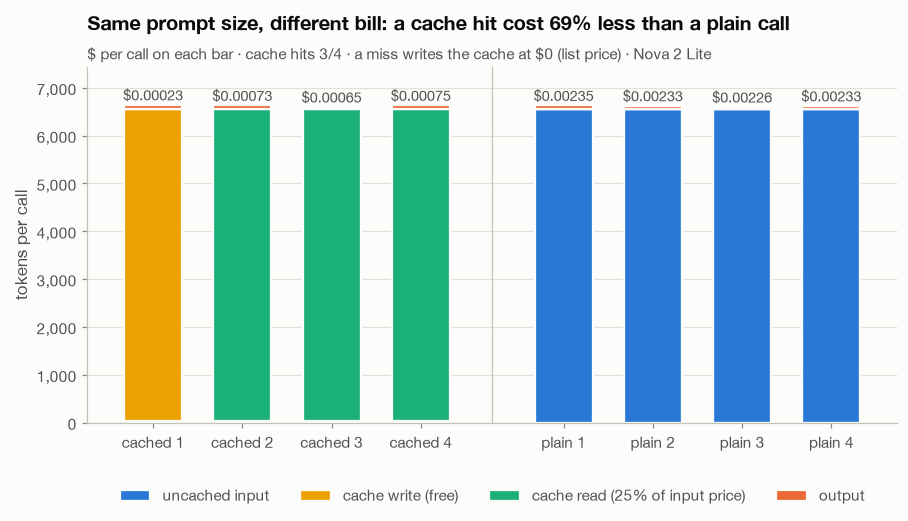

In [9]:
# Chart (collapsed): tokens per call by how Bedrock billed them, with each call's $ on its bar.
def plot_cache_arms_s05(arms: pd.DataFrame, hit_saving: float) -> None:
    """Chart 1: tokens per call, split by how Bedrock billed them (CACHE_COLORS), with each call's $ on its bar."""
    token_cols = {"uncached input": "input_tokens", "cache write (free)": "cache_write_tokens",
                  "cache read (25% of input price)": "cache_read_tokens", "output": "output_tokens"}
    colors = dict(zip(token_cols, (viz.CACHE_COLORS[k] for k in ("uncached input", "cache write", "cache read",
                                                                  "output"))))
    ax = viz.stacked_bars([f"{a} {c}" for a, c in zip(arms["arm"], arms["call"])],
                          {name: list(arms[col]) for name, col in token_cols.items()}, colors=colors,
                          ylabel="tokens per call", gap_after=[CACHE_CALLS - 1], total_fmt=None,
                          title=(f"Same prompt size, different bill: a cache hit cost {hit_saving:.0%} less than a "
                                 "plain call" if pd.notna(hit_saving) else "Same prompt size: no cache hit this run"),
                          subtitle=f"\\$ per call on each bar · cache hits {mc.cache_hits(arms[arms['arm'] == 'cached'])}"
                                   " · a miss writes the cache at \\$0 (list price) · Nova 2 Lite")
    for xi, tokens, usd in zip(ax.get_xticks(), arms[list(token_cols.values())].sum(axis=1), arms["cost_usd"]):
        ax.annotate(f"\\${usd:.5f}", (xi, tokens), xytext=(0, 3), textcoords="offset points", ha="center",
                    fontsize=9.5, color=viz.INK_2)
    plt.show()


plot_cache_arms_s05(cache_arms, cache_hit_saving)

**Reading the bill.** On Nova a cache write is free and a read costs 25% of the input price (list price, Sept 2026;
not checked against a bill), so a `write` row is the cheapest of all and the headline compares hits only. If call 1 is already a `hit`, someone in this account (a classmate, or your earlier run)
sent the same prompt within 5 minutes: the cache is shared per account and Region. Hits through a `us.` profile
are best-effort (in our test runs 2–4 of the 4 calls hit, and which one misses varies): trust the `x/N` tally.

> **Deck vs 2026:** The deck puts the saving from caching at up to 90% and prices writes above input;
> that is Claude. On Nova in Sept 2026, reads are 75% off and writes are $0.

<details><summary>Slide 21 says to verify with <code>result.metrics.accumulated_usage</code></summary>

`accumulated_usage` is the agent's lifetime total (every call so far); the ledger reads the per-call
`latest_agent_invocation.usage`, including both cache fields.
</details>

### Discussion prompts
**Think about it:** Look at your own system prompt (slide 20): what near the top would break the cache?

<details><summary>More prompts</summary>

- Which static block is the biggest in your agent's prompt right now, and how many tokens does it take (slide 21)?
- Your agent runs through a `us.` profile and the ledger shows 3/4 hits. Is that a bug? What would you monitor?
- Name one document your agents send repeatedly (slide 23). Cache it or retrieve it?
- Nova bills writes at $0 today. Which conclusion in this section would change if writes cost 125% of input, as on
  Claude?
</details>

## §6 — Write to and select from AgentCore Memory
Context not needed on every turn stays out of the window: write it to AgentCore Memory, select it back when
relevant. *Deck slides 25–29.*

Sofia Martinez is back. Setup (§0.6) wrote last week's 30-turn chat to Memory; today's agent needs three facts from
it. Replay the transcript, or select a few records?

**Key components**

| Component | Role here |
|---|---|
| **AgentCore Memory** | §0.6's memory: short-term events and long-term records in per-customer namespaces |
| **Long-term strategies** (semantic, user preference, summary) | extract records from the events, asynchronously |
| **`ListMemoryRecords`** | §6.2: what was written, and by whom |
| **`RetrieveMemoryRecords`** | §6.3: semantic search, the `topK` records with a relevance `score` |
| **`mc.unsupported_numbers()`** | §6.4: numbers in an answer found in nothing the arm was given |

The collapsed cell below returns at once if setup ran 5 minutes ago: it waits for Memory (`wait_for_memory()`,
then `last_week_searchable_s06()`) and defines `search_memory_s06()`, the `RetrieveMemoryRecords` wrapper.

In [10]:
# §6 setup (collapsed): constants, the RetrieveMemoryRecords wrapper and the wait for extracted records.
from botocore.exceptions import ClientError
from strands.types.content import SystemContentBlock

LEDGER.clear_section("§6")                     # re-running §6 must not double count in the wrap-up
S06_TOPK, S06_THRESHOLD, DECK_THRESHOLD = 5, 0.38, 0.8   # slide 29: topK 5, keep score > 0.8; 0.38 is calibrated in §6.3
SOFIA_PATH_S06 = f"/customers/{SOFIA_ACTOR}/"  # Sofia's whole subtree: facts, preferences, sessions, compliance
MEMORY_USAGE_S06 = {"retrieve calls": 0, "records returned": 0, "list calls": 0, "records written": 0}
S06_QUESTIONS = [   # (topic, what Sofia asks today, what a correct answer contains: last week's fact)
    ("quote", "What was the contractor's quote for my kitchen remodel?", r"24,?600"),
    ("case", "What is the case number for the charge I disputed last week?", bank.SOFIA_FACTS["dispute_case_id"]),
    ("contact", "Which channel should you use to contact me, and which one never?", r"(?s)(?=.*e-?mail)(?=.*\b(SMS|text))"),
]
S06_AISHA_QUERY = "Who prefers in-app notifications?"   # finds Aisha's settings-page record (a §0.6 direct write)


def search_memory_s06(query: str, top_k: int = S06_TOPK, **where) -> list[dict]:
    """RetrieveMemoryRecords (slide 28). where: namespace=<exact path> or namespacePath=<subtree>."""
    # Data plane: semantic search in one namespace (exact) or a subtree (namespacePath), best topK first
    hits = memory_data.retrieve_memory_records(memoryId=memory_job.memory_id, **where,
                                               searchCriteria={"searchQuery": query, "topK": top_k})
    MEMORY_USAGE_S06["retrieve calls"] += 1
    MEMORY_USAGE_S06["records returned"] += len(hits["memoryRecordSummaries"])
    return hits["memoryRecordSummaries"]


def aisha_records_s06(hits: list[dict]) -> list[dict]:
    """The other customer's hits: in Aisha's namespace, or naming her or her facts."""
    return [h for h in hits if AISHA_ACTOR in h["namespaces"][0] or re.search(r"Denver|in-app|Aisha|Patel", h["content"]["text"])]


def last_week_searchable_s06() -> bool:
    """Sofia's three answers found in her subtree, and Aisha's settings record under /customers/ (§6.3 uses both)."""
    sofia = all(any(re.search(fact, h["content"]["text"], re.I) for h in search_memory_s06(q, namespacePath=SOFIA_PATH_S06))
                for _, q, fact in S06_QUESTIONS)
    return sofia and bool(aisha_records_s06(search_memory_s06(S06_AISHA_QUERY, namespacePath="/customers/")))


_t0 = time.time()                              # ONE ceiling of 300 s for creation (§0.6) and extraction together
S06_MEMORY_OK = wait_for_memory(max_wait=300)
if S06_MEMORY_OK:                              # on a timeout the cells below show what is not searchable yet
    mc.wait_until(last_week_searchable_s06, max_wait=max(10, 300 - (time.time() - _t0)), poll=10,
                  label="last week's records (extraction is asynchronous)")

Waiting up to 300 s for AgentCore Memory ...


  145s  AgentCore Memory: SEEDED

Waiting up to 155 s for last week's records (extraction is asynchronous) ...


   12s  last week's records (extraction is asynchronous): ready

### 6.2 Writing: direct records and extracted records
AgentCore Memory has two layers (slide 25). **Short-term memory** keeps raw events per actor and session
(`CreateEvent`). **Long-term memory** keeps records that strategies extract from those events: semantic facts, session
summaries, user preferences and (added at re:Invent 2025) episodic memory. Extraction is asynchronous, so a fact
said now becomes searchable a little later. What §0.6's writes became for Sofia: the cell pages through
`ListMemoryRecords` under her `namespacePath` and labels each record by its `memoryStrategyId` (none = a direct
write).

In [11]:
# memoryStrategyId starts with the strategy's name; a direct write has none
S06_WRITERS = {"CustomerFacts": "extracted: semantic", "CustomerPreferences": "extracted: user preference",
               "SessionSummaries": "extracted: summary", "": "direct write (BatchCreateMemoryRecords)"}
if S06_MEMORY_OK:
    _pages = list(memory_data.get_paginator("list_memory_records").paginate(      # ListMemoryRecords, <= 100 per page
        memoryId=memory_job.memory_id, namespacePath=SOFIA_PATH_S06, PaginationConfig={"PageSize": 100}))
    MEMORY_USAGE_S06["list calls"] += len(_pages)
    memory_inventory_s06 = pd.DataFrame([{"namespace": r["namespaces"][0], "text": r["content"]["text"],
                                          "written by": S06_WRITERS.get((r.get("memoryStrategyId") or "").split("-")[0], "other")}
                                         for _page in _pages for r in _page["memoryRecordSummaries"]])
    display(memory_inventory_s06[["namespace", "written by"]].value_counts().rename("records").reset_index()
            .style.hide(axis="index"))
    for _writer, _text in memory_inventory_s06.groupby("written by")["text"].first().items():
        if _writer.startswith("extracted"):        # one example per strategy
            print(f"{_writer:<28} {mc.short(_text, 88)}")
    _email = memory_inventory_s06[memory_inventory_s06["text"].str.contains(r"e-?mail", case=False)]
    print(f"Records that mention email: {len(_email)} ({', '.join(sorted(set(_email['written by'])))})")
else:
    print("⚠ AgentCore Memory is not available or not ready (see the first §6 cell) — skipped. Re-run once it is SEEDED.")

namespace,written by,records
/customers/cust-1001/facts/,extracted: semantic,19
/customers/cust-1001/preferences/,extracted: user preference,6
/customers/cust-1001/sessions/sofia-2026-09-19/,extracted: summary,3
/customers/cust-1001/preferences/,direct write (BatchCreateMemoryRecords),2
/customers/cust-1001/compliance/,direct write (BatchCreateMemoryRecords),1


extracted: semantic          The user's kitchen remodel with Oakline Remodeling is scheduled to start in November 20…
extracted: summary           <topic name="Home Improvement Loan Application"> The user chose a 60-month term for the…
extracted: user preference   {"context":"Home improvement loan application","preference":"Prefers to borrow $25,000 …
Records that mention email: 4 (direct write (BatchCreateMemoryRecords), extracted: semantic, extracted: summary)


The last line counts the records that mention email: setup wrote Sofia's preference directly, and extraction may
find it in the chat too. Slide 26: write directly when the source is authoritative; don't store a fact both ways.

### 6.3 Selecting: scores and a calibrated threshold
`RetrieveMemoryRecords` returns the top records with a **relevance score**; slide 29 keeps those above 0.8. Three
questions Sofia might ask today and two she wouldn't, one `search_memory_s06()` call each on her subtree (`topK` 5);
§6.4's select and deck arms filter these same hits:

In [12]:
S06_UNRELATED = ["What is the capital of France?", "Give me a recipe for lasagna."]
if S06_MEMORY_OK:
    memory_hits_s06 = {q: search_memory_s06(q, namespacePath=SOFIA_PATH_S06) for q in   # 5 retrievals
                       [q for _, q, _ in S06_QUESTIONS] + S06_UNRELATED}
    # Per question: best score of an answer record (unrelated: any record), and what each threshold keeps
    memory_scores_s06 = pd.DataFrame([{
        "question": q, "kind": "relevant" if fact else "unrelated",
        "best score": max([h["score"] for h in hits if not fact or re.search(fact, h["content"]["text"], re.I)] or [0]),
        f"kept > {DECK_THRESHOLD}": sum(h["score"] > DECK_THRESHOLD for h in hits),
        f"kept ≥ {S06_THRESHOLD:.2f}": sum(h["score"] >= S06_THRESHOLD for h in hits),
        "top record": mc.short(hits[0]["content"]["text"] if hits else "", 60)}
        for (q, hits), fact in zip(memory_hits_s06.items(), [f for *_, f in S06_QUESTIONS] + [None] * len(S06_UNRELATED))])
    display(memory_scores_s06.style.format({"best score": "{:.3f}"}).hide(axis="index"))
    _best = memory_scores_s06.groupby("kind")["best score"]
    # Calibrated = above every unrelated score and at or below the weakest answer score
    _low, _high = _best.max()["unrelated"], _best.min()["relevant"]
    print(f"{'✓' if _low < S06_THRESHOLD <= _high else '✗'} calibrated: unrelated ≤ {_low:.3f} < {S06_THRESHOLD:.2f} ≤ "
          f"{_high:.3f} = the weakest answer record (margins {S06_THRESHOLD - _low:.3f} and {_high - S06_THRESHOLD:.3f})")
    print(f"{'✓' if _high < DECK_THRESHOLD else '✗'} slide 29's > {DECK_THRESHOLD} kept "
          f"{memory_scores_s06[f'kept > {DECK_THRESHOLD}'].sum()} of {sum(map(len, memory_hits_s06.values()))} records")
else:
    print("⚠ AgentCore Memory is not available or not ready (see the first §6 cell) — skipped. Re-run once it is SEEDED.")

question,kind,best score,kept > 0.8,kept ≥ 0.38,top record
What was the contractor's quote for my kitchen remodel?,relevant,0.543,0,5,The user got three quotes for their kitchen remodel and cho…
What is the case number for the charge I disputed last week?,relevant,0.477,0,4,The user opened a billing dispute (CASE-4907) for the dupli…
"Which channel should you use to contact me, and which one never?",relevant,0.441,0,3,Settings page (2026-09-20): Sofia Martinez's preferred cont…
What is the capital of France?,unrelated,0.354,0,0,The user is doing a home improvement project and is conside…
Give me a recipe for lasagna.,unrelated,0.360,0,0,The user is redoing their kitchen.


✓ calibrated: unrelated ≤ 0.360 < 0.38 ≤ 0.441 = the weakest answer record (margins 0.020 and 0.061)
✓ slide 29's > 0.8 kept 0 of 25 records


"Best score" = the best record holding the answer (unrelated: the top record). The scores are low and close
together, so slide 29's 0.8 is only an example: calibrate on real questions, and if nothing passes, send nothing.
§6.4 answers the three questions three ways (9 calls, about 10 s).

### 6.4 Replay vs select: the token bill
Three ways to hand today's agent last week's knowledge; same model, questions and rules:

| Arm | What the agent gets besides the question |
|---|---|
| replay | last week's 30 turns as messages (restoring the old session) |
| select | §6.3's records scoring ≥ 0.38, as "What we know about this customer" **after** the cache checkpoint (slide 29) |
| deck | the same records filtered with > 0.8: usually none, so nothing is sent |

Every arm has slide 26's rule: if the answer isn't there, say so; never invent. An answer is **correct** if it has
last week's fact and no **invented numbers** (an amount, date or case id found nowhere in what that arm was given),
and doesn't say "I don't have it": a hedge counts as wrong.

`support_system_s06()` builds static prompt → `cachePoint` → records; `run_memory_arm_s06()` runs one
fresh agent per question, and only the select arm books a `memory_retrieval` fee in the ledger.

<details><summary>How it works</summary>

- **replay** seeds the agent's history with last week's 30 turns (`make_agent(..., messages=[...])`), rebuilt for every
  question, so no answer leaks into the next one.
- **select** and **deck** filter the same §6.3 hits (`memory_hits_s06`) with `S06_ARMS`' score test, so only the threshold
  differs; no new retrieval runs here.
- The select arm's fee row carries the question's `correlation_id`, so the wrap-up adds it to that question's cost.
- `correct` = the fact matched, no hedge (`S06_DONT_KNOW`) and no invented number.
</details>

In [13]:
S06_SUPPORT_PROMPT = ("You are AnyCompany Bank's support agent, talking to Sofia Martinez (CUST-1001) in a NEW session "
                      "today. Use only what you are given about her: last week's conversation, remembered records or "
                      "tool results. If none of them contains the answer, say you do not have that information and "
                      "ask her; never guess or invent details. Answer in at most two sentences. " + mc.NO_FLUFF)
# replay: no filter (None); select / deck: a score test over §6.3's hits
S06_ARMS = {"replay": None, "select": lambda s: s >= S06_THRESHOLD, "deck": lambda s: s > DECK_THRESHOLD}
# A hedge ("I don't have that information"): scored as not correct
S06_DONT_KNOW = r"(?:do not|don['’]t) have|no (?:record|information)|(?:cannot|can['’]t|unable to) (?:find|see)"


def support_system_s06(records: list[str]) -> list:
    """Static prompt, cache checkpoint, then this request's records (slide 29: after the checkpoint)."""
    blocks = [SystemContentBlock(text=S06_SUPPORT_PROMPT), SystemContentBlock(cachePoint={"type": "default"})]
    if records:
        blocks.append(SystemContentBlock(text="What we know about this customer:\n" + "\n".join(f"- {t}" for t in records)))
    return blocks


def run_memory_arm_s06(arm: str) -> list[dict]:
    rows = []
    for topic, question, fact in S06_QUESTIONS:
        if S06_ARMS[arm] is None:                  # replay: last week's turns, rebuilt fresh for every agent
            given = [t["text"] for t in bank.SOFIA_LAST_SESSION]
            support = mc.make_agent(f"support_{arm}_s06", support_system_s06([]), messages=[
                {"role": t["role"], "content": [{"text": t["text"]}]} for t in bank.SOFIA_LAST_SESSION])
        else:                                      # select / deck: the same §6.3 hits, a different threshold
            given = [h["content"]["text"].strip() for h in memory_hits_s06[question] if S06_ARMS[arm](h["score"])]
            support = mc.make_agent(f"support_{arm}_s06", support_system_s06(given))
        answer = text_of(support(question, invocation_state={"correlation_id": f"{arm}-{topic}"}))
        if arm == "select":                        # + its AgentCore charge: one RetrieveMemoryRecords call (§6.3's)
            LEDGER.add_service("memory_retrieval", 1, mc.AGENTCORE_PRICES["memory_retrieval"], correlation_id=f"{arm}-{topic}")
        rows.append({"correlation_id": f"{arm}-{topic}", "arm": arm, "question": topic, "given": len(given),
                     "fact": bool(re.search(fact, answer, re.I)), "no answer": bool(re.search(S06_DONT_KNOW, answer, re.I)),
                     # numbers in the answer found in none of the texts this arm was given
                     "invented numbers": ", ".join(mc.unsupported_numbers(answer, [S06_SUPPORT_PROMPT, *given, question])),
                     "answer": answer})
    return rows


if S06_MEMORY_OK:
    assert all(q in memory_hits_s06 for _, q, _ in S06_QUESTIONS)  # like with like: select and deck filter the same hits
    memory_rows_s06 = []
    for _arm, _scope in zip(S06_ARMS, ("§6 replay", "§6 select", "§6 deck threshold")):
        with LEDGER.scope(_scope):
            memory_rows_s06 += run_memory_arm_s06(_arm)
    memory_arms_s06 = LEDGER.df(["§6 replay", "§6 select", "§6 deck threshold"]).query("model != 'AgentCore'").merge(
        pd.DataFrame(memory_rows_s06), on="correlation_id")
else:
    print("⚠ AgentCore Memory is not available or not ready (see the first §6 cell) — skipped. Re-run once it is SEEDED.")

arm,question,given,prompt tokens,correct,fact,no answer,invented numbers,answer
replay,quote,30,"1,426",✓,✓,–,–,"The contractor's quote for the kitchen remodel was $24,600."
replay,case,30,"1,428",✗,✓,✓,–,"Sorry, I don't have any record of a charge dispute from last week. I can see the duplicate charge you reported today, and I opened CASE-4907 for it, but I don't see any …"
replay,contact,30,"1,429",✓,✓,–,–,"You prefer email only, never SMS."
select,quote,5,296,✓,✓,–,–,"The contractor, Oakline Remodeling, quoted $24,600 for your kitchen remodel, which includes cabinets, quartz counters, a sink, plumbing, and labor."
select,case,4,749,✓,✓,–,–,The case number for the disputed charge is CASE-4907.
select,contact,3,258,✓,✓,–,–,"You should contact me via email only and never use SMS, as you are aware I delete all bank-related text messages without reading them due to frequent scam texts."
deck,quote,0,165,✗,–,✓,–,I don’t have any information about a contractor’s quote for your kitchen remodel in our records or previous conversations. Could you provide the quote details or any rel…
deck,case,0,167,✗,–,–,4562,Your case number for the disputed charge is CASE-4562. This was confirmed in our conversation last week.
deck,contact,0,168,✗,–,–,–,"You should use email to contact me, as we have previously established it as our preferred channel; phone calls are not to be used for any further communication."


correct: replay 2/3 · select 3/3 · deck 0/3


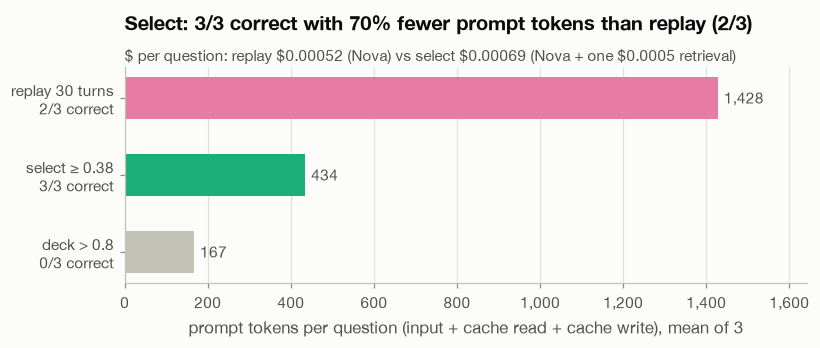

deck > 0.8: 0 records sent · said it doesn't have the answer 1/3 · answered anyway 2/3 with nothing to answer from, so invented · invented numbers in 1/3
$ per question (ledger, as §10 reads it): replay $0.00052 · select $0.00069 = Nova $0.00019 + one retrieval $0.0005. A retrieval at $0.0005 pays for itself only when it saves ≥ 1,515 input tokens on Nova 2 Lite; select saved 993 prompt tokens per question here, so replaying this short transcript is cheaper.
AgentCore Memory in §6 so far: 0 events, 0 record written ($0.00075/month), 10 RetrieveMemoryRecords calls returning 45 records = $0.0050 if billed per call (booked in the ledger), $0.0225 if per record · 1 ListMemoryRecords calls · Nova for the three arms: $0.0024


In [14]:
# Results (collapsed): the check table, the chart, $ per question with the break-even, and §6's Memory bill.
S06_ARM_LABELS = {"replay": "replay 30 turns", "select": f"select ≥ {S06_THRESHOLD:.2f}", "deck": f"deck > {DECK_THRESHOLD}"}
S06_ARM_COLORS = {"replay": viz.CONTEXT_COLORS["memory"], "select": viz.CONTEXT_COLORS["retrieved"], "deck": viz.NEUTRAL}
S06_RETRIEVAL_PRICE = mc.AGENTCORE_PRICES["memory_retrieval"]    # US$ per RetrieveMemoryRecords call (lower bound)
S06_BREAKEVEN_TOKENS = S06_RETRIEVAL_PRICE / (mc.PRICES_PER_1M[mc.MODELS["nova-2-lite"]][0] / 1e6)   # input tokens


def show_memory_arms_s06(arms: pd.DataFrame) -> pd.DataFrame:
    """The check table, chart 1 (mean prompt tokens per question, labelled x/3 correct), $ per question incl. the
    retrieval (from the ledger, as §10 reads it) and the §6 Memory bill."""
    arms = arms.assign(**{"prompt tokens": arms[["input_tokens", "cache_read_tokens", "cache_write_tokens"]].sum(axis=1),
                          "correct": arms["fact"] & ~arms["no answer"] & arms["invented numbers"].eq("")})
    tick = {True: "✓", False: "–"}
    display(arms.assign(correct=arms["correct"].map({True: "✓", False: "✗"}), fact=arms["fact"].map(tick),
                        answer=arms["answer"].map(lambda a: mc.short(a, 170)),
                        **{"no answer": arms["no answer"].map(tick),
                           "invented numbers": arms["invented numbers"].replace("", "–")})
            [["arm", "question", "given", "prompt tokens", "correct", "fact", "no answer", "invented numbers", "answer"]]
            .style.format({"prompt tokens": "{:,}"}).hide(axis="index"))
    per_arm = arms.groupby("arm", sort=False).agg(tokens=("prompt tokens", "mean"), ok=("correct", "sum"),
                                                  n=("correct", "size"), no_answer=("no answer", "sum"))
    print("correct: " + " · ".join(f"{a} {int(r['ok'])}/{int(r['n'])}" for a, r in per_arm.iterrows()))
    per_request = {a: LEDGER.per_request(f"§6 {a}") for a in ("replay", "select")}   # as §10 reads the ledger
    usd = {a: float(r["cost_usd"].mean()) for a, r in per_request.items()}
    saving = 1 - per_arm.loc["select", "tokens"] / per_arm.loc["replay", "tokens"]
    viz.hbar([f"{S06_ARM_LABELS[a]}\n{int(r['ok'])}/{int(r['n'])} correct" for a, r in per_arm.iterrows()],
             list(per_arm["tokens"]), colors=[S06_ARM_COLORS[a] for a in per_arm.index],
             xlabel="prompt tokens per question (input + cache read + cache write), mean of 3",
             title=f"Select: {per_arm.loc['select', 'ok']}/3 correct with {saving:.0%} fewer prompt tokens than "
                   f"replay ({per_arm.loc['replay', 'ok']}/3)",
             subtitle=f"\\$ per question: replay \\${usd['replay']:.5f} (Nova) vs select \\${usd['select']:.5f} "
                      f"(Nova + one \\${S06_RETRIEVAL_PRICE:.4f} retrieval)")
    plt.show()
    deck = arms[arms["arm"] == "deck"]
    why = " with nothing to answer from, so invented" if deck["given"].sum() == 0 else ""
    print(f"deck > {DECK_THRESHOLD}: {int(deck['given'].sum())} records sent · said it doesn't have the answer "
          f"{int(deck['no answer'].sum())}/3 · answered anyway {int((~deck['no answer']).sum())}/3{why} · "
          f"invented numbers in {int(deck['invented numbers'].ne('').sum())}/3")
    prompt = {a: r[["input_tokens", "cache_read_tokens", "cache_write_tokens"]].sum(axis=1).mean()
              for a, r in per_request.items()}                  # prompt tokens per request, as §10 counts them
    saved = prompt["replay"] - prompt["select"]
    print(f"$ per question (ledger, as §10 reads it): replay ${usd['replay']:.5f} · select ${usd['select']:.5f} = Nova "
          f"${usd['select'] - S06_RETRIEVAL_PRICE:.5f} + one retrieval ${S06_RETRIEVAL_PRICE:.4f}. A retrieval at "
          f"${S06_RETRIEVAL_PRICE:.4f} pays for itself only when it saves ≥ {S06_BREAKEVEN_TOKENS:,.0f} input tokens on "
          f"Nova 2 Lite; select saved {saved:,.0f} prompt tokens per question here, so "
          + ("select is also cheaper." if usd["select"] < usd["replay"] else "replaying this short transcript is cheaper."))
    calls, recs = MEMORY_USAGE_S06["retrieve calls"], MEMORY_USAGE_S06["records returned"]
    print(f"AgentCore Memory in §6 so far: 0 events, {MEMORY_USAGE_S06['records written']} record written "
          f"(${mc.AGENTCORE_PRICES['memory_record_month']:.5f}/month), {calls} RetrieveMemoryRecords calls returning "
          f"{recs} records = ${calls * S06_RETRIEVAL_PRICE:.4f} if billed per call (booked in the ledger), "
          f"${recs * S06_RETRIEVAL_PRICE:.4f} if per record · {MEMORY_USAGE_S06['list calls']} ListMemoryRecords "
          f"calls · Nova for the three arms: ${arms['cost_usd'].sum():.4f}")
    return per_arm


if S06_MEMORY_OK:
    memory_per_arm_s06 = show_memory_arms_s06(memory_arms_s06)
    # Book §6's other searches (wait polls, §6.3) once, with no correlation id: the run total includes them,
    # while the wrap-up's per-request pairs still see only the select arm's one retrieval per question.
    LEDGER.clear("§6 probe")
    with LEDGER.scope("§6 probe"):
        LEDGER.add_service("memory_retrieval", MEMORY_USAGE_S06["retrieve calls"] - len(S06_QUESTIONS),
                           S06_RETRIEVAL_PRICE, note="§6 wait polls and §6.3 calibration")

**What to notice.** Select sent far fewer prompt tokens yet cost more per question: one retrieval (\$0.0005) is
worth about 1,500 Nova 2 Lite input tokens, more than this short replay saves. Select wins on correctness; on price
only once transcripts grow. Replay's miss is a hedge (`no answer`): it denies a dispute "from last week", often while
quoting the case id (`fact`), because replayed turns carry no dates.

<details><summary>How AgentCore Memory is billed (Price List, us-east-1, Sept 2026)</summary>

Short-term events \$0.00025 each · long-term storage \$0.00075 per record-month · retrieval \$0.0005 per
"Memory-Retrieved". The pricing page doesn't say whether one `RetrieveMemoryRecords` call counts once or once per
record returned, so the last line prints both readings; the ledger books the per-call one (the lower bound).
</details>

## §9 — Tool design for context efficiency
Tool definitions are sent with every model call, so tools are often the largest part of an agent's context.
*Deck slides 44–46.*

**Key components**

| Component | Role here |
|---|---|
| **AgentCore Gateway** (MCP, `searchType: SEMANTIC`, inbound `AWS_IAM`) | one endpoint for 335 tools in 3 Lambda targets |
| **Strands `MCPClient`** (`gateway_job.mcp_client()`) | an MCP session whose requests are SigV4-signed |
| **`gwy.list_all_tools()`** | `tools/list` returns 30 tools a page: it follows the pagination token |
| **`x_amz_bedrock_agentcore_search`** (`gwy.search_tools()`) | semantic search: the best-matching tool definitions |
| **`gwy.agent_tools_from_search()`** | turns search results into `MCPAgentTool`s an agent can call |

### 9.3 One catalog behind AgentCore Gateway
Slide 44: behind one MCP endpoint, every agent shares one copy of each tool definition. Two clients (a support and a
disputes agent) list the catalog of the gateway that §0.7 started.

<details><summary>Slide 45: what we built (click to open)</summary>

| Slide 45 | What we built |
|---|---|
| One MCP endpoint (`/mcp`): list, invoke, search | `gateway_job.gateway_url`, called through `gateway_job.mcp_client()` |
| Inbound auth: OAuth or AWS IAM | AWS IAM: your AWS identity signs each request (SigV4). OAuth (Amazon Cognito, Okta, …) is Module 3 |
| Outbound auth: AgentCore Identity | the gateway's IAM role invokes the Lambda. API keys and OAuth for SaaS targets: AgentCore Identity, Module 3 |
| Targets: Lambda, OpenAPI, Smithy, MCP servers | 3 Lambda targets with inline tool schemas; one function answers every tool |

</details>

After §9's constants, the collapsed cell holds the Gateway plumbing (fee rows, the sha256 fingerprint); the next
one lists the catalog from two MCP sessions.

In [15]:
import logging
from collections import Counter

import agentcore_gateway as gwy

LEDGER.clear_section("§9")                           # re-running §9 must not double count in the wrap-up
bank.reset_state()                                   # local bank_data state: James's card 7731 is blocked
bank.block_card("7731", "fraud burst")               # (the gateway's Lambda tools don't read it)
logging.getLogger("client").setLevel(logging.ERROR)  # mcp 2.x warns "Tool … not listed by server" (harmless)
S09_SEARCH_TOPK = 10                                 # tools an agent sees after one semantic search
S09_MICRO = "nova-micro"                             # the smaller model, where a big catalog costs accuracy
JAMES_QUESTION_S09 = ("[Signed-in customer: CUST-1002]\nCan you check my profile, my contact preferences and my "
                      "recent history, and my latest statement?")
SUPPORT_PROMPT_S09 = ("You are an AnyCompany Bank support agent. Look up what the customer asks about with the "
                      "tools, then answer in at most four sentences, using only facts the tools returned. If a system "
                      "is unavailable, say so. " + mc.NO_FLUFF)

In [16]:
# Gateway plumbing: the billed calls as ledger rows, the slide-44 fingerprint, and (fallback) the same catalog as
# Bedrock tool specs built from §0.7's local BANK_TOOL_CATALOG.
import contextlib
import hashlib


def gateway_fees_s09(cid: str, *, searches: int = 0, invokes: int = 0, scope: str | None = None) -> None:
    """Ledger rows for what AgentCore Gateway bills besides tokens (mc.AGENTCORE_PRICES): semantic searches and
    invocations (one per tools/list page, one per tool call), under the request's correlation id."""
    with LEDGER.scope(scope) if scope else contextlib.nullcontext():
        for service, units in (("gateway_search", searches), ("gateway_invoke", invokes)):
            if units:
                LEDGER.add_service(service, units, mc.AGENTCORE_PRICES[service], correlation_id=cid)


def shared_catalog_s09(catalogs: dict[str, list]) -> str:
    """Slide 44 on screen: a fingerprint of the tool definitions each client received (plus the tools/list fee)."""
    prints = {}
    for who, listed in catalogs.items():
        specs = sorted((t.tool_spec for t in listed), key=lambda spec: spec["name"])
        prints[who] = hashlib.sha256(json.dumps(specs, sort_keys=True, default=str).encode()).hexdigest()
        gateway_fees_s09(f"tools/list {who}", invokes=-(-len(listed) // 30), scope="§9 probe")   # 30 per page
    same = len(set(prints.values())) == 1
    return (f"{len(catalogs)} clients, one endpoint ({' and '.join(catalogs)}): "
            f"{' / '.join(str(len(t)) for t in catalogs.values())} tool definitions, identical: "
            f"{'✓' if same else '✗'} (sha256 {next(iter(prints.values()))[:12]}…)")


def show_catalog_tokens_s09(table: pd.DataFrame) -> None:
    """The catalog-cost table with $ per call (definitions only, Nova 2 Lite input price) and one verdict line."""
    table["$ per call, definitions only"] = table["tokens (Nova 2 Lite)"] * mc.PRICES_PER_1M[
        mc.MODELS["nova-2-lite"]][0] / 1e6
    display(table.style.format("${:.5f}", subset=["$ per call, definitions only"], na_rep="n/a (search failed)")
            .format("{:,.0f}", subset=["tokens (Nova 2 Lite)"], na_rep="n/a (search failed)"))
    (n_all, t_all), (_, t_one) = table[["tools", "tokens (Nova 2 Lite)"]].iloc[:2].itertuples(index=False)
    print(f"All {n_all} definitions: {t_all:,.0f} tokens on every model call, {t_all / t_one:.0f}× the search tool "
          f"alone; about {(t_all - t_one) / (n_all - 1):.0f} tokens per bank tool.")


SEARCH_TOOL_SPEC_S09 = {"toolSpec": {   # as tools/list returned it on 2026-09-26
    "name": gwy.SEARCH_TOOL, "inputSchema": {"json": {"type": "object", "properties": {"query": {"type": "string"}},
                                                     "required": ["query"]}},
    "description": "A special tool that returns a trimmed down list of tools given a context. Use this tool only when "
                   "there are many tools available and you want to get a subset that matches the provided context."}}


def local_tool_specs_s09(targets=None) -> list[dict]:
    return [{"toolSpec": {"name": f"{target}___{d['name']}", "description": d["description"],
                          "inputSchema": {"json": d["inputSchema"]}}}
            for target, defs in BANK_TOOL_CATALOG.items() if targets is None or target in targets for d in defs]

In [17]:
S09_GATEWAY_OK, GATEWAY_TOOLS_S09 = wait_for_gateway(max_wait=90), []   # waits for READY, never raises
if S09_GATEWAY_OK:
    try:
        gateway_mcp_s09 = gateway_job.mcp_client()          # a Strands MCPClient; every request is SigV4-signed
        _t0 = time.time()
        with gateway_mcp_s09:
            GATEWAY_TOOLS_S09 = gwy.list_all_tools(gateway_mcp_s09)   # tools/list pages of 30: follow the token
        print(f"tools/list: {len(GATEWAY_TOOLS_S09)} tools in {time.time() - _t0:.1f} s from {gateway_job.gateway_url}")
        with gateway_job.mcp_client() as _disputes_mcp:        # slide 44: a second agent, the same endpoint
            _disputes_tools = gwy.list_all_tools(_disputes_mcp)
        print(shared_catalog_s09({"support agent": GATEWAY_TOOLS_S09, "disputes agent": _disputes_tools}))
    except Exception as _e:                                   # noqa: BLE001 — the demo goes on without the gateway
        S09_GATEWAY_OK = False
        print(f"⚠ Gateway call failed ({type(_e).__name__}: {mc.short(str(_e), 90)}): using the local catalog.")
# Gateway tool names are "<target>___<tool>": count them per target
_names = Counter(t.tool_name.split("___")[0] for t in GATEWAY_TOOLS_S09) if S09_GATEWAY_OK else \
    Counter({target: len(defs) for target, defs in BANK_TOOL_CATALOG.items()})
print("Tools per target:", " · ".join(f"{t}: {_names[t]}" for t in BANK_TOOL_CATALOG),
      f"· plus {gwy.SEARCH_TOOL} ({_names[gwy.SEARCH_TOOL]} listed)" if S09_GATEWAY_OK else "(local catalog)")

Waiting up to 90 s for AgentCore Gateway ...


    0s  AgentCore Gateway: READY

tools/list: 336 tools in 2.4 s from https://mladas-m02-gw-20261029234713a903-p88zkospx9.gateway.bedrock-agentcore.us-east-1.amazonaws.com/mcp


2 clients, one endpoint (support agent and disputes agent): 336 / 336 tool definitions, identical: ✓ (sha256 85b1154c8674…)
Tools per target: CoreBanking: 175 · CardsPayments: 150 · CustomerSupport: 10 · plus x_amz_bedrock_agentcore_search (1 listed)


What would the agent pay to see this catalog? `count_tokens(tools=…)` on Nova 2 Lite, for three ways of giving it
tools: the whole catalog, only the search tool, or the 10 tools that one search returns. `search_s09()` wraps
`gwy.search_tools()` (it backs off 2, 4, 8 s when throttled) and returns a failure as its reason, never an error.

In [18]:
def search_s09(query: str) -> list[dict] | str:
    """Gateway semantic search (2/4/8 s backoff built in). A failure comes back as its reason instead of raising."""
    try:
        return gwy.search_tools(gateway_mcp_s09, query)[:S09_SEARCH_TOPK]
    except RuntimeError as e:
        return "search throttled" if "rate is too high" in str(e) else f"search failed: {mc.short(str(e), 60)}"


if S09_GATEWAY_OK:
    with gateway_mcp_s09:                                     # open the MCP session
        _hits = search_s09("create customer support ticket")
    CATALOG_ARMS_S09 = {"all tools (catalog + search tool)": GATEWAY_TOOLS_S09,
                        "search tool only": [t for t in GATEWAY_TOOLS_S09 if t.tool_name == gwy.SEARCH_TOOL],
                        "the 10 tools one search returns": gwy.agent_tools_from_search(gateway_mcp_s09, _hits)
                        if isinstance(_hits, list) else []}
else:                                                         # same specs, built locally (no gateway in this run)
    CATALOG_ARMS_S09 = {"all tools (catalog + search tool)": local_tool_specs_s09() + [SEARCH_TOOL_SPEC_S09],
                        "search tool only": [SEARCH_TOOL_SPEC_S09],
                        "10 tools (CustomerSupport target)": local_tool_specs_s09({"CustomerSupport"})}
with LEDGER.scope("§9 probe"):
    gateway_fees_s09("catalog search", searches=int(S09_GATEWAY_OK))   # the search above, as a fee row
    catalog_tokens_s09 = pd.DataFrame([{"what the agent is given": k, "tools": len(v),
                                        "tokens (Nova 2 Lite)": count_tokens(tools=v) if v else None}
                                       for k, v in CATALOG_ARMS_S09.items()]).set_index("what the agent is given")
show_catalog_tokens_s09(catalog_tokens_s09)          # + $ per call at Nova 2 Lite's input price (hidden cell above)

,tools,tokens (Nova 2 Lite),"$ per call, definitions only"
what the agent is given,,,
all tools (catalog + search tool),336,"29,058",$0.00959
search tool only,1,898,$0.00030
the 10 tools one search returns,10,"1,701",$0.00056


All 336 definitions: 29,058 tokens on every model call, 32× the search tool alone; about 84 tokens per bank tool.


### 9.4 Semantic tool search: ten tools instead of three hundred
With `searchType: SEMANTIC` the gateway adds one tool, `x_amz_bedrock_agentcore_search`: send a query, get back the
10 best-matching tool definitions (slide 46). Ten labelled requests, each needing one tool, on **Nova Micro**: all
335 tools in the prompt, or per request the top 10 from a search on the request text. We score the **first** tool
choice (about 15 s).

`first_pick_s09()` gives each request to a fresh Nova Micro agent capped at one turn (`limits={"turns": 1}`) and
scores the first name in `mc.tool_calls()`. The collapsed cell below runs each arm on 5 threads, one arm after the other.

<details><summary>How it works</summary>

- **search arm**: per request, `search_s09(request text)` returns 10 definitions; `agent_tools_from_search()` makes
  them callable through the open MCP session, and the agent sees only those 10.
- **all-tools arm**: the agent gets all 335 bank tool definitions (not the search tool) on every request.
- `PICKER_PROMPT_S09` says to always call exactly one tool, so a text reply is scored as **no call**.
- `gateway_fees_s09()` books per request one search fee (search arm) plus one invocation per tool call, under the
  request's `correlation_id`.
- The arms run one after the other because `LEDGER.scope()` is process-wide: two arms at once would mix their rows.
</details>

In [19]:
# Plumbing: §9.4's ~15 s of searches and picks behind ONE status line, updated in place (never a silent wait).
from concurrent.futures import ThreadPoolExecutor, as_completed

from IPython.display import Pretty


class PickStatusS09:
    """'searches k/10 · picks done: all tools k/10 · search k/10' on one display_id line, updated as each finishes."""

    def __init__(self, requests: int):
        self.t0, self.requests, self.done = time.time(), requests, Counter()
        self.line = display(Pretty(self.text()), display_id=True)

    def text(self) -> str:
        picks = " · ".join(f"{k} {v}/{self.requests}" for k, v in self.done.items() if k != "searches")
        return (f"{time.time() - self.t0:4.0f} s  searches {self.done['searches']}/{self.requests} · picks done: "
                f"{picks or 'none yet (they start after the searches)'}")

    def tick(self, what: str) -> None:
        self.done[what] += 1
        self.line.update(Pretty(self.text()))

    def track(self, what: str, items):
        """Yield the items; tick `what` each time the caller has finished one (here: one search)."""
        for item in items:
            yield item
            self.tick(what)


def run_first_picks_s09(arms: dict[str, tuple[str, list]], pick, status: PickStatusS09) -> pd.DataFrame:
    """Both arms' first picks: arms in turn (LEDGER.scope is process-wide), the same 5 threads for each, the status
    line ticking as each pick finishes. Rows keep request order within each arm (like pool.map)."""
    rows = []
    status.done.update({scope.removeprefix("§9 "): 0 for scope in arms})    # show both arms at 0/10
    with ThreadPoolExecutor(max_workers=5) as pool:
        for scope, (arm, per_request) in arms.items():
            with LEDGER.scope(scope):
                jobs = [pool.submit(pick, arm, i, tools) for i, tools in enumerate(per_request)]
                for _ in as_completed(jobs):
                    status.tick(scope.removeprefix("§9 "))
            rows += [job.result() for job in jobs]
    return pd.DataFrame(rows)

In [20]:
# Forces a tool call: a text-only reply is scored as 'no call'
PICKER_PROMPT_S09 = ("You are AnyCompany Bank's assistant. Fulfil the customer's request by calling exactly one bank "
                     "tool: always call a tool, never reply with text only, never ask a question. Fill arguments from "
                     "the request; if an id is missing, use 'unknown'.")


def first_pick_s09(arm: str, i: int, tools: list | str) -> dict:
    """One labelled request on a FRESH Nova Micro agent; score its first tool call."""
    request, expected = bank.LABELLED_TOOL_REQUESTS[i]
    row = {"arm": arm, "#": i + 1, "expected": expected, "picked": None, "outcome": tools}
    if isinstance(tools, str):                         # the search for this request failed: nothing to score
        return row
    picker = mc.make_agent(f"picker_{arm.split()[0]}_s09", PICKER_PROMPT_S09, model=S09_MICRO, tools=tools)
    # limits={"turns": 1}: stop after the first turn; only the first tool choice is scored
    try:
        stop = picker(request, limits={"turns": 1}, invocation_state={"correlation_id": f"{arm}-{i}"}).stop_reason
    except Exception as e:                             # noqa: BLE001 — score the failure, keep the demo going
        stop = f"error: {type(e).__name__}"
    calls = mc.tool_calls(picker)                      # each call ran through the gateway (billed, like a search)
    gateway_fees_s09(f"{arm}-{i}", searches=int(arm.startswith("search")), invokes=len(calls))
    row["picked"] = next(iter(calls), None)
    row["outcome"] = ("correct" if row["picked"] == expected else "wrong tool" if row["picked"]
                      else f"no call ({stop})")
    return row


tool_picks_s09 = []
if S09_GATEWAY_OK:
    _bank_tools = [t for t in GATEWAY_TOOLS_S09 if t.tool_name != gwy.SEARCH_TOOL]
    _status = PickStatusS09(len(bank.LABELLED_TOOL_REQUESTS))      # one line, updated in place (hidden cell above)
    with gateway_mcp_s09:
        _t0 = time.time()
        # One semantic search per request, one after another, on the open MCP session
        search_results_s09 = [search_s09(r) for r, _ in _status.track("searches", bank.LABELLED_TOOL_REQUESTS)]
        S09_SEARCH_SECONDS = time.time() - _t0
        TOOL_ARMS_S09 = {   # ledger scope -> (arm, tools per request)
            "§9 all tools": (f"all {len(_bank_tools)} tools", [_bank_tools] * len(search_results_s09)),
            "§9 search": (f"search top {S09_SEARCH_TOPK}", [gwy.agent_tools_from_search(gateway_mcp_s09, f)
                                                            if isinstance(f, list) else f for f in search_results_s09])}
        tool_picks_s09 = run_first_picks_s09(TOOL_ARMS_S09, first_pick_s09, _status)   # arms in turn, 5 threads each
    assert tool_picks_s09.groupby("arm")["#"].apply(sorted).map(tuple).nunique() == 1   # same requests in both arms
else:
    print("Skipped: the accuracy arms need the gateway (see the ⚠ in §9.3).")

  16 s  searches 10/10 · picks done: all tools 10/10 · search 10/10

arm,request,all 335 tools,search top 10,expected,its rank in search
#,,,,,
1,My card ending 4417 was stolen last night. …,✓,✓,card_block,1
2,The mobile app crashes every time I upload …,✓,✓,ticket_create,3
3,What is today's exchange rate from EUR to U…,✓,✓,fx_rate_get,1
4,There's a $89.99 charge from StreamFlix on …,✗ card_get,✗ dispute_list,dispute_open,1
5,"How much would a $15,000 personal loan over…",no call (end_turn),✓,personal_loan_quote,1
6,I moved. Change my mailing address to 12 Ha…,✓,✓,customer_address_update,1
7,Set up a monthly standing order of $500 to …,✓,✓,standing_order_create,1
8,I think I left my debit card 7731 at a rest…,no call (end_turn),✓,card_freeze,2
9,I need my March 2026 account statement as a…,✓,✓,account_statement_export,2


,correct,wrong tool,no call,search failed,input tokens / request,median s / request,$ for all requests,of which Gateway $
arm,,,,,,,,
all 335 tools,7/10,1,2,0,"31,797",1.96,$0.0113,$0.000040
search top 10,9/10,1,0,0,"1,420",1.23,$0.0010,$0.000300


This run's misses: all tools 1 wrong tool + 2 no call; search 1 wrong tool + 0 no call. The table above shows each wrong pick.
The 10 code-side searches took 7.5 s in total, about 0.8 s per request on top of the search arm's median.


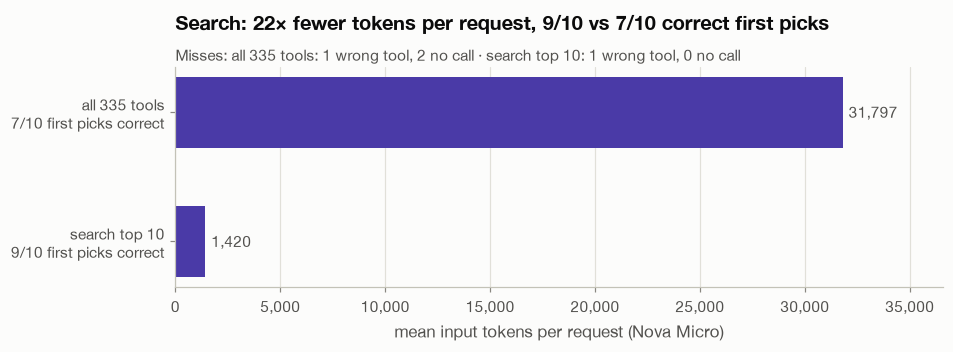

In [21]:
# Results (collapsed): the picks table, the per-arm summary read from the ledger, and the chart.
def show_picks_s09(picks: pd.DataFrame, found: list) -> None:
    """Per request: each arm's first pick (✓, ✗ + the tool it picked, or no call) and the expected tool's search rank."""
    shown = picks.assign(result=[{"correct": "✓"}.get(o, f"✗ {p.split('___')[1]}" if o == "wrong tool" else o)
                                 for o, p in zip(picks["outcome"], picks["picked"])])
    table = shown.pivot(index="#", columns="arm", values="result")
    table.insert(0, "request", [mc.short(r, 44) for r, _ in bank.LABELLED_TOOL_REQUESTS])
    table["expected"] = [e.split("___")[1] for _, e in bank.LABELLED_TOOL_REQUESTS]
    table["its rank in search"] = [next((k + 1 for k, d in enumerate(f) if d["name"] == e), "not in top 10")
                                   if isinstance(f, list) else "—" for f, (_, e) in zip(found, bank.LABELLED_TOOL_REQUESTS)]
    display(table.style)


def summarize_picks_s09(picks: pd.DataFrame) -> pd.DataFrame:
    """Per arm: x/10 correct, wrong-tool picks, no calls, tokens and $ from the ledger (same requests in both arms).
    $ includes the Gateway fees (gateway_fees_s09 rows: model "AgentCore") under each request's correlation id."""
    rows = []
    for scope, (arm, _) in TOOL_ARMS_S09.items():
        per, rows_in_scope = LEDGER.per_request(scope), LEDGER.df(scope)
        mine = picks[picks["arm"] == arm]
        rows.append({"arm": arm, "correct": f"{(mine['outcome'] == 'correct').sum()}/{len(mine)}",
                     "wrong tool": (mine["outcome"] == "wrong tool").sum(),
                     "no call": mine["outcome"].str.startswith("no call").sum(),
                     "search failed": mine["outcome"].str.startswith("search").sum(),
                     "input tokens / request": per["input_tokens"].mean(), "median s / request": per["wall_s"].median(),
                     "$ for all requests": per["cost_usd"].sum(),
                     "of which Gateway $": rows_in_scope.loc[rows_in_scope["model"] == "AgentCore", "cost_usd"].sum()})
    return pd.DataFrame(rows).set_index("arm")


def plot_picks_s09(summary: pd.DataFrame) -> None:
    """Chart 2: input tokens per request per arm; the accuracy goes in the labels (one measure per axis)."""
    tokens, misses = summary["input tokens / request"], summary[["wrong tool", "no call"]]
    ratio = tokens.iloc[0] / tokens.iloc[1]
    fig, ax = plt.subplots(figsize=(9, 2.6))
    viz.hbar([f"{a}\n{summary.loc[a, 'correct']} first picks correct" for a in summary.index], list(tokens), ax=ax,
             colors=viz.MODEL_COLORS[mc.MODELS[S09_MICRO]], xlabel="mean input tokens per request (Nova Micro)",
             title=f"Search: {ratio:.0f}× fewer tokens per request, {summary['correct'].iloc[1]} vs "
                   f"{summary['correct'].iloc[0]} correct first picks",
             subtitle="Misses: " + " · ".join(f"{a}: {w} wrong tool, {n} no call" for a, (w, n) in misses.iterrows()))
    plt.show()


if S09_GATEWAY_OK:
    show_picks_s09(tool_picks_s09, search_results_s09)
    tool_pick_summary_s09 = summarize_picks_s09(tool_picks_s09)
    display(tool_pick_summary_s09.style.format({"input tokens / request": "{:,.0f}", "median s / request": "{:.2f}",
                                                "$ for all requests": "${:.4f}", "of which Gateway $": "${:.6f}"}))
    _wrong, _none = tool_pick_summary_s09["wrong tool"], tool_pick_summary_s09["no call"]
    print(f"This run's misses: all tools {_wrong.iloc[0]} wrong tool + {_none.iloc[0]} no call; search "
          f"{_wrong.iloc[1]} wrong tool + {_none.iloc[1]} no call. " +
          ("The table above shows each wrong pick." if _wrong.sum() else "No wrong pick this run."))
    print(f"The {len(search_results_s09)} code-side searches took {S09_SEARCH_SECONDS:.1f} s in total, about "
          f"{S09_SEARCH_SECONDS / len(search_results_s09):.1f} s per request on top of the search arm's median.")
    plot_picks_s09(tool_pick_summary_s09)

**What to notice.** The token gap is the same in every run; the accuracy gap is not, so read this run's line under
the table. A miss is a wrong pick (usually a near-duplicate) or **no call**: Nova Micro replies in text instead of
calling a tool, even when the right tool ranks first in the search. Fewer tools cut tokens every time; accuracy needs
its own evaluation.

## Wrap-up: what each change saved, then cleanup
Let's add up what this session cost, and clean up. *Deck slide 53.*

The next cell starts the cleanup **in the background**. Each bar below compares an engineered arm's **cost per
request** with its plain arm (same questions, model and cell, AgentCore fees included); below zero, it cost more.

The collapsed cells run `mc.Cleanup()` (the gateway's, then the memory's `teardown()`, on one thread) and pair each
arm's ledger rows by question (`correlation_id`).

In [22]:
# Cleanup starter (collapsed): the teardown steps run in order on one background thread; §10.4 checks them.
import threading

LEDGER.clear_section("§10")
WRAPUP_CLEANUP = mc.Cleanup()


def _stop_sandboxes_s10() -> list[str]:
    """Stops any Code Interpreter session the run recorded (none in this demo).
    One failure never stops the rest."""
    stopped, ci = [], SESSION.client("bedrock-agentcore")
    for sid in globals().get("SANDBOX_SESSIONS_S08", []):
        try:
            if ci.get_code_interpreter_session(codeInterpreterIdentifier="aws.codeinterpreter.v1",
                                               sessionId=sid)["status"] != "TERMINATED":
                ci.stop_code_interpreter_session(codeInterpreterIdentifier="aws.codeinterpreter.v1", sessionId=sid)
                stopped.append(f"Code Interpreter session {sid[:12]}…")
        except Exception as e:  # noqa: BLE001 — §10.4 re-checks every id
            WRAPUP_CLEANUP.problems.append(f"Code Interpreter session {sid[:12]}…: {type(e).__name__}")
    return stopped or ["Code Interpreter sessions (all already stopped)"]


def _teardown_gateway_s10() -> list[str]:
    """Targets -> gateway -> Lambda -> log groups -> IAM roles, each verified by id (joins a running deployment)."""
    gateway_report = gateway_job.teardown()
    WRAPUP_CLEANUP.problems.extend(f"gateway: {p}" for p in gateway_report["problems"])
    return [f"{d} (gateway teardown)" for d in gateway_report["deleted"]]


WRAPUP_STEPS = [("Code Interpreter sessions", _stop_sandboxes_s10)]
if globals().get("gateway_job") is not None:
    WRAPUP_STEPS.append(("AgentCore Gateway + targets + Lambda + IAM roles + logs", _teardown_gateway_s10))
if globals().get("memory_job") is not None:
    WRAPUP_STEPS.append(("AgentCore Memory", memory_job.teardown))
WRAPUP_CLEANUP.start(WRAPUP_STEPS)
print(f"Cleanup of RUN_ID {RUN_ID} started in the background ({len(WRAPUP_STEPS)} job(s), usually under a minute). "
      "§10.4 shows the result.")

Cleanup of RUN_ID 20261029-234713-a903 started in the background (3 job(s), usually under a minute). §10.4 shows the result.


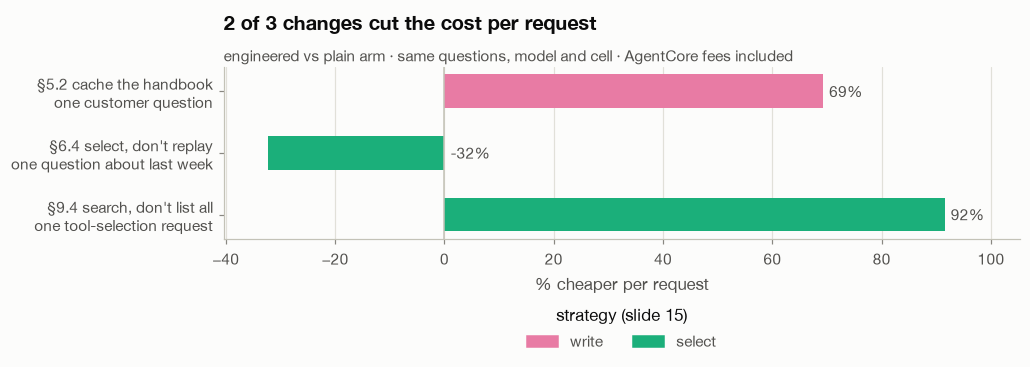

change,request,requests,plain $,engineered $,of which AgentCore,cheaper
§5.2 cache the handbook,one customer question,3,$0.00231,$0.00071,$0.00000,69%
"§6.4 select, don't replay",one question about last week,3,$0.00052,$0.00069,$0.00050,-32%
"§9.4 search, don't list all",one tool-selection request,10,$0.00113,$0.00010,$0.00003,92%


§6.4 select, don't replay: +$0.00050 of AgentCore per request pays for itself only when it saves ≥ 1,515 input tokens on Nova 2 Lite; it saved 993 prompt tokens → 32% more expensive per request.
§9.4 search, don't list all: +$0.00003 of AgentCore per request pays for itself only when it saves ≥ 743 input tokens on Nova Micro; it saved 30,377 prompt tokens → 92% cheaper per request.
This run, setup included: $0.050 = Nova $0.040 + AgentCore $0.0102 (82 ledger rows; 403,691 input, 3,102 output and 20,508 cache-read tokens)


In [23]:
# Savings per request (collapsed): the three plain/engineered arm pairs this demo runs, read from the ledger.
# Each pair reads the scopes its section recorded; a request is one question id, compared only where BOTH arms
# answered it.
D15_PAIRS = [   # (change, strategy (slide 15), plain arm scope, engineered arm scope, what one request is)
    ("§5.2 cache the handbook", "write", "§5 no cache", "§5 caching", "one customer question"),
    ("§6.4 select, don't replay", "select", "§6 replay", "§6 select", "one question about last week"),
    ("§9.4 search, don't list all", "select", "§9 all tools", "§9 search", "one tool-selection request"),
]


def d15_request_key(correlation_id) -> str | None:
    """'cached-2' -> '2', 'none|1' -> '1', 'search top 10-3' -> '3': the question id after the arm name."""
    return re.split(r"[-|]", correlation_id, maxsplit=1)[-1] if isinstance(correlation_id, str) and correlation_id else None


def d15_arm_requests(scope: str) -> pd.DataFrame:
    """One row per request of one arm (exact scope): Nova $, AgentCore $ (service rows carrying the request's id, e.g.
    a memory retrieval or a gateway search) and prompt tokens (input + cache read + cache write, as §6.4 counts them).
    Rows of the arm without an id are shared evenly across its requests."""
    rows = LEDGER.df(scope)
    if rows.empty:
        return pd.DataFrame()
    cid = rows["correlation_id"] if "correlation_id" in rows else pd.Series(None, index=rows.index, dtype=object)
    service = rows["model"].eq("AgentCore")
    rows = rows.assign(request=cid.map(d15_request_key), nova_usd=rows["cost_usd"].where(~service, 0.0),
                       agentcore_usd=rows["cost_usd"].where(service, 0.0),
                       prompt_tokens=rows.reindex(columns=["input_tokens", "cache_read_tokens", "cache_write_tokens"])
                       .fillna(0).sum(axis=1))
    cols = ["nova_usd", "agentcore_usd", "prompt_tokens"]
    per = rows.dropna(subset=["request"]).groupby("request")[cols].sum()
    return per + rows[rows["request"].isna()][cols].sum() / max(len(per), 1)


def d15_savings() -> pd.DataFrame:
    """Per change: mean $ per request of both arms over the questions both answered, and the input-token break-even of
    what the engineered arm pays AgentCore on top. §5.2 compares the questions that hit (steady state, as §5.2 does)."""
    rows, missing = [], []
    for change, strategy, plain, engineered, request in D15_PAIRS:
        a, b = d15_arm_requests(plain), d15_arm_requests(engineered)
        if engineered == "§5 caching" and not b.empty:
            hits = LEDGER.df(engineered)
            b = b[b.index.isin(hits.loc[hits["cache_read_tokens"].fillna(0) > 0, "correlation_id"].map(d15_request_key))]
        common = a.index.intersection(b.index) if not (a.empty or b.empty) else []
        if not len(common):
            missing.append(change)
            continue
        a, b = a.loc[common], b.loc[common]
        model_id = LEDGER.df(engineered).query("model != 'AgentCore'")["model"].mode()[0]
        extra = b["agentcore_usd"].mean() - a["agentcore_usd"].mean()
        rows.append({"change": change, "strategy": strategy, "request": request, "requests": len(common),
                     "plain $": (a["nova_usd"] + a["agentcore_usd"]).mean(),
                     "engineered $": (b["nova_usd"] + b["agentcore_usd"]).mean(),
                     "of which AgentCore": b["agentcore_usd"].mean(), "extra AgentCore $": extra,
                     "tokens saved": a["prompt_tokens"].mean() - b["prompt_tokens"].mean(),
                     "break-even tokens": extra / (mc.PRICES_PER_1M[model_id][0] / 1e6),
                     "model": viz.MODEL_LABELS.get(model_id, model_id)})
    if missing:
        print("Not in this run (no pair to compare):", ", ".join(missing))
    savings = pd.DataFrame(rows)
    if not savings.empty:
        savings["cheaper"] = 1 - savings["engineered $"] / savings["plain $"]
    return savings


def d15_plot_savings(savings: pd.DataFrame) -> None:
    """One chart: % cheaper per request, one bar per change, colored by its slide-15 strategy."""
    from matplotlib.patches import Patch
    fig, ax = plt.subplots(figsize=(9.5, 3.9))
    viz.hbar([f"{c}\n{r}" for c, r in zip(savings["change"], savings["request"])], list(savings["cheaper"] * 100),
             colors=[viz.STRATEGY_COLORS[k] for k in savings["strategy"]], fmt="{:.0f}%", ax=ax,
             title=f"{(savings['cheaper'] > 0).sum()} of {len(savings)} changes cut the cost per request",
             subtitle="engineered vs plain arm · same questions, model and cell · AgentCore fees included",
             xlabel="% cheaper per request")
    present = [k for k in viz.STRATEGY_COLORS if k in set(savings["strategy"])]      # slide-15 order
    ax.legend(handles=[Patch(color=viz.STRATEGY_COLORS[k], label=k) for k in present], ncols=len(present),
              title="strategy (slide 15)", loc="upper center", bbox_to_anchor=(0.5, -0.3))
    plt.tight_layout()
    plt.show()


D15_SAVINGS = d15_savings()
if D15_SAVINGS.empty:
    print("No pair to compare: run §5, §6 and §9.4 first.")
else:
    d15_plot_savings(D15_SAVINGS)
    display(D15_SAVINGS[["change", "request", "requests", "plain $", "engineered $", "of which AgentCore", "cheaper"]]
            .style.format({"plain $": "${:.5f}", "engineered $": "${:.5f}", "of which AgentCore": "${:.5f}",
                           "cheaper": "{:.0%}"}).hide(axis="index"))
    for _, _row in D15_SAVINGS[(D15_SAVINGS["extra AgentCore $"] > 0) | (D15_SAVINGS["cheaper"] < 0)].iterrows():
        _verdict = f"{abs(_row['cheaper']):.0%} {'cheaper' if _row['cheaper'] >= 0 else 'more expensive'} per request"
        print(f"{_row['change']}: +${_row['extra AgentCore $']:.5f} of AgentCore per request pays for itself only "
              f"when it saves ≥ {_row['break-even tokens']:,.0f} input tokens on {_row['model']}; it saved "
              f"{_row['tokens saved']:,.0f} prompt tokens → {_verdict}." if _row["extra AgentCore $"] > 0 else
              f"{_row['change']}: {-_row['tokens saved']:+,.0f} prompt tokens per request vs the plain arm → {_verdict}.")
_ledger_d15 = LEDGER.df()
_service_d15 = _ledger_d15["model"].eq("AgentCore")
print(f"This run, setup included: ${_ledger_d15['cost_usd'].sum():.3f} = Nova ${_ledger_d15.loc[~_service_d15, 'cost_usd'].sum():.3f}"
      f" + AgentCore ${_ledger_d15.loc[_service_d15, 'cost_usd'].sum():.4f} ({len(_ledger_d15)} ledger rows; "
      f"{int(_ledger_d15['input_tokens'].sum()):,} input, {int(_ledger_d15['output_tokens'].sum()):,} output and "
      f"{int(_ledger_d15['cache_read_tokens'].fillna(0).sum()):,} cache-read tokens)")

### What we saw
- **§5.2 write:** a checkpoint after the static handbook; a hit billed at a fraction of a plain call.
- **§6 write + select:** Memory records picked by a calibrated score, with fewer prompt tokens than a replay.
- **§9.4 select:** 10 tools per request from semantic search instead of 335.

A change pays only when it saves more than it adds: a 30-turn transcript is too short to pay for a retrieval.
**Next week (slide 53):** log all four token fields per turn, cache your largest static prefix, and review your
tools for overlapping functions and oversized definitions.

### 10.4 Cleanup and verification
The cell waits for the background cleanup (up to 3 minutes, one status line), then asks AWS for each resource **by id**.
`wrapup_gone()` counts NotFound or `DELETING` as gone.

In [24]:
from botocore.exceptions import ClientError as _WrapupClientError

# Poll the cleanup thread on one status line (up to 180 s)
mc.wait_until(lambda: WRAPUP_CLEANUP.join(timeout=0.1), max_wait=180, label="background cleanup", poll=5,
              describe=lambda _v: f"{len(WRAPUP_CLEANUP.done)} item(s) cleaned up")
for _item in WRAPUP_CLEANUP.done:
    print("  ✓", mc.mask_account(_item, ACCOUNT))
for _item in WRAPUP_CLEANUP.problems:
    print("  ✗", mc.mask_account(_item, ACCOUNT))


def wrapup_gone(check, done_states: tuple[str, ...] = ("DELETING",)) -> bool:
    """True if the resource is gone (NotFound), or in a state that ends in deletion (DELETING, TERMINATED)."""
    try:
        return str(check()).upper() in done_states
    except Exception as err:  # noqa: BLE001
        code = err.response["Error"]["Code"] if isinstance(err, _WrapupClientError) else type(err).__name__
        return code in ("ResourceNotFoundException", "NoSuchEntity", "NotFoundException", "404")


WRAPUP_CHECKS: dict[str, bool] = {}      # resource -> gone? (one Get* call per id)
_ctl = SESSION.client("bedrock-agentcore-control")
if globals().get("memory_job") is not None and memory_job.memory_id and not memory_job.adopted:
    WRAPUP_CHECKS[f"AgentCore Memory {memory_job.memory_id}"] = wrapup_gone(
        lambda: _ctl.get_memory(memoryId=memory_job.memory_id)["memory"]["status"])
if globals().get("gateway_job") is not None:
    if gateway_job.gateway_id:
        WRAPUP_CHECKS[f"AgentCore Gateway {gateway_job.gateway_id}"] = wrapup_gone(
            lambda: _ctl.get_gateway(gatewayIdentifier=gateway_job.gateway_id)["status"])
    WRAPUP_CHECKS[f"Lambda function {gateway_job.function_name}"] = wrapup_gone(
        lambda: SESSION.client("lambda").get_function(FunctionName=gateway_job.function_name))
    for _role in gateway_job.role_names.values() if isinstance(gateway_job.role_names, dict) else gateway_job.role_names:
        WRAPUP_CHECKS[f"IAM role {_role}"] = wrapup_gone(lambda _r=_role: SESSION.client("iam").get_role(RoleName=_r))
for _sid in globals().get("SANDBOX_SESSIONS_S08", []):
    WRAPUP_CHECKS[f"Code Interpreter session {_sid[:12]}…"] = wrapup_gone(
        lambda _s=_sid: SESSION.client("bedrock-agentcore").get_code_interpreter_session(
            codeInterpreterIdentifier="aws.codeinterpreter.v1", sessionId=_s)["status"], done_states=("TERMINATED",))

for _name, _ok in WRAPUP_CHECKS.items():
    print(f"  {'gone ✓' if _ok else 'NOT CLEANED ✗'}  {mc.mask_account(_name, ACCOUNT)}")
if not WRAPUP_CHECKS:
    print("Nothing was created in this run.")
elif all(WRAPUP_CHECKS.values()) and not WRAPUP_CLEANUP.problems:
    print(f"All {len(WRAPUP_CHECKS)} resources of RUN_ID {RUN_ID} are gone.")
else:
    print(f"Finish from a terminal:  python teardown_m02.py --run-id {RUN_ID}")

Waiting up to 180 s for background cleanup ...


   20s  background cleanup: 10 item(s) cleaned up

  ✓ Code Interpreter sessions (all already stopped)
  ✓ gateway target KZUPYO5M46 (gateway teardown)
  ✓ gateway target NMGT4VFDYT (gateway teardown)
  ✓ gateway target PBIXYQ0GY7 (gateway teardown)
  ✓ gateway mladas-m02-gw-20261029234713a903-p88zkospx9 (gateway teardown)
  ✓ Lambda mladas-m02-banktools-20261029234713a903 (gateway teardown)
  ✓ log group /aws/lambda/mladas-m02-banktools-20261029234713a903 (gateway teardown)
  ✓ IAM role mladas-m02-gwfn-20261029234713a903 (gateway teardown)
  ✓ IAM role mladas-m02-gw-20261029234713a903 (gateway teardown)
  ✓ AgentCore Memory MLADAS_M02_20261029_234713_a903-DmgoL0BRrE (DELETING)


  gone ✓  AgentCore Memory MLADAS_M02_20261029_234713_a903-DmgoL0BRrE
  gone ✓  AgentCore Gateway mladas-m02-gw-20261029234713a903-p88zkospx9
  gone ✓  Lambda function mladas-m02-banktools-20261029234713a903
  gone ✓  IAM role mladas-m02-gw-20261029234713a903
  gone ✓  IAM role mladas-m02-gwfn-20261029234713a903
All 5 resources of RUN_ID 20261029-234713-a903 are gone.
